# 05 · GAN-Generated Fakes and an Adversarial Forger

Notebooks 01 to 04 test the detectors on diffusion models only (Stable Diffusion 1.4, 2.1 and 3.0). This notebook checks whether the conclusions still hold for the other major family of image generators: **generative adversarial networks (GANs)** (Goodfellow et al., 2014). GANs are also where the "forger vs detective" idea behind this project comes from. A GAN's generator is trained to fool a discriminator, so the last section turns that idea against the detectors themselves.

**No detector is retrained.** The 16 models from notebook 02 (2 architectures × 2 training setups × 3 seeds, plus 4 augmented models) are evaluated exactly as they are, so every result here is a test on a generator family the detectors have never seen.

| Forger | Where it comes from | Role in the study |
|---|---|---|
| Conditional DCGAN | Trained in this notebook on CIFAR-10 training images (Radford et al., 2016; Mirza & Osindero, 2014) | A weak, older-style GAN |
| StyleGAN2-ADA | NVIDIA's pretrained class-conditional CIFAR-10 model (Karras et al., 2020) | A strong, modern GAN |
| Adversarial DCGAN | The DCGAN fine-tuned to fool one specific detector | A forger that knows its detective |

| Section | Question |
|---|---|
| 1 | How were the existing images saved as JPEG, so that the GAN fakes can be saved the same way? |
| 2 | Training the DCGAN |
| 3 | Loading StyleGAN2-ADA |
| 4 | Building the GAN test sets (clean and blurred) |
| 5 | How realistic are the GAN images (FID)? |
| 6 | How accurate is each detector on GAN fakes? |
| 7 | Is the CNN vs ViT difference significant? |
| 8 | Does a recalibrated cut-off recover accuracy on GAN fakes? |
| 9 | How are the P(fake) scores distributed? |
| 10 | How do the detectors cope when real and GAN images are both blurred? |
| 11 | What do GAN fingerprints look like in the frequency spectrum? |
| 12 | Where do the detectors look on GAN images (Grad-CAM)? |
| 13 | Are some object classes harder to catch? |
| 14 | Can a forger be trained to fool a specific detector, and does the trick transfer? |
| 15 | Summary of key results |

**Outputs:** GAN images in `outputs/data/gan/`, GAN checkpoints in `outputs/models/gan/`, tables in `outputs/results/` and figures in `outputs/figures/`. All of them start with `05_`. Every expensive step saves its result to Google Drive, so after a disconnect the notebook carries on from where it stopped.

In [34]:
# Environment setup
%pip install -q -U timm grad-cam kagglehub "torchmetrics[image]"

import copy
import hashlib
import io
import json
import os
import subprocess
import sys
import time
import types
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import timm
from PIL import Image, ImageFilter, JpegImagePlugin
from scipy.stats import binomtest
from sklearn.metrics import confusion_matrix, f1_score, precision_score, roc_auc_score
from torchvision.transforms.functional import gaussian_blur
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from tqdm.auto import tqdm
from IPython.display import Markdown, display
from google.colab import drive, userdata

# Colab's local disk is wiped when the session ends, so all outputs live in Google Drive
drive.mount("/content/drive")
PROJECT_DIR = Path("/content/drive/MyDrive/MAAI901_AIImageDetector")

DATA_DIR = PROJECT_DIR / "outputs" / "data"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
FIG_DIR = PROJECT_DIR / "outputs" / "figures"
GAN_DATA_DIR = DATA_DIR / "gan"              # generated images and the GAN test sets
GAN_MODEL_DIR = MODEL_DIR / "gan"            # GAN checkpoints
PRED_DIR = RESULTS_DIR / "predictions"       # cached P(fake) scores, shared with notebook 03
for folder in (DATA_DIR, MODEL_DIR, RESULTS_DIR, FIG_DIR, GAN_DATA_DIR, GAN_MODEL_DIR, PRED_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
REAL, FAKE = 0, 1                      # FAKE is the positive class (the detection target)
LABEL_NAMES = {REAL: "REAL", FAKE: "FAKE"}
TRAIN_SETUPS = ("trainSD14", "trainSD21")
SD_TEST_SETS = {                       # test sets from notebook 01 (diffusion fakes)
    "test_sd14": "SD 1.4",
    "test_sd21": "SD 2.1",
    "test_sd30": "SD 3.0",
    "test_sd21blur": "SD 2.1 blurred",
}
CIFAR10_CLASSES = ("airplane", "automobile", "bird", "cat", "deer",
                   "dog", "frog", "horse", "ship", "truck")

# Two ImageNet-pretrained models of similar size (23.5M vs 21.7M parameters),
# so the comparison isolates architecture rather than capacity.
MODELS = {
    "resnet50": {"timm_id": "resnet50.a1_in1k", "family": "cnn",
                 "display_name": "ResNet-50 (CNN)", "lr": 1e-4, "timm_kwargs": {}},
    "vit_small": {"timm_id": "vit_small_patch16_224.augreg_in21k_ft_in1k", "family": "vit",
                  "display_name": "ViT-S/16 (Transformer)", "lr": 5e-5, "timm_kwargs": {}},
}
INPUT_SIZE = 224
SEEDS = (42, 1, 2)
AUG_SEEDS = (42,)


def run_name(setup, model_key, seed=42, augment=False):
    # File name of a training run. Seed-42 runs without augmentation keep the original names.
    name = f"{setup}__{model_key}"
    if augment:
        name += "__aug"
    if seed != 42:
        name += f"__s{seed}"
    return name


RUNS = ([(s, m, 42, False) for s in TRAIN_SETUPS for m in MODELS]
        + [(s, m, seed, True) for s in TRAIN_SETUPS for m in MODELS for seed in AUG_SEEDS]
        + [(s, m, seed, False) for seed in SEEDS if seed != 42 for s in TRAIN_SETUPS for m in MODELS])

# GAN experiment settings
N_FAKE = 10_000                        # GAN fakes per test set, 1,000 per CIFAR-10 class
FAKE_CLASSES = np.repeat(np.arange(len(CIFAR10_CLASSES)), N_FAKE // len(CIFAR10_CLASSES))
GEN_SEED = 2027                        # seed for the latent vectors of every generated test image
BLUR_RADIUS = 2                        # px; the strength matched to Jiang's blurred set in notebook 01
N_BOOTSTRAP = 1_000
BLUR_SIGMAS = (0.0, 0.5, 1.0, 1.5, 2.0, 3.0)
ROBUSTNESS_IMAGES = 4_000
GRADCAM_IMAGES = 400

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

# One fixed colour per model across every figure, as in notebooks 01-04
MODEL_COLORS = {"resnet50": "#2a78d6", "vit_small": "#eb6834"}
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e4df",
    "axes.axisbelow": True, "axes.edgecolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False,
})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: Tesla T4


The detector code below is the same as in notebooks 02 to 04: the resize to 224×224 and the normalisation live inside the model, so the GAN images are preprocessed exactly like every other test image. `load_detector` follows the pattern from notebook 04, with the seed and augmentation added so that all 16 checkpoints can be loaded.

In [35]:
class Detector(nn.Module):
    # Pretrained timm backbone with built-in preprocessing (identical to notebooks 02-04).

    def __init__(self, spec, input_size=INPUT_SIZE, pretrained=True):
        super().__init__()
        self.spec = dict(spec)
        self.family = spec["family"]
        self.input_size = input_size
        self.backbone = timm.create_model(spec["timm_id"], pretrained=pretrained,
                                          num_classes=2, **spec["timm_kwargs"])
        cfg = timm.data.resolve_model_data_config(self.backbone)
        self.register_buffer("mean", torch.tensor(cfg["mean"]).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("std", torch.tensor(cfg["std"]).view(1, 3, 1, 1), persistent=False)

    def preprocess(self, x):
        # Float NCHW in [0, 1] at any size -> normalised NCHW at input_size
        if x.shape[-2:] != (self.input_size, self.input_size):
            x = F.interpolate(x, size=(self.input_size, self.input_size),
                              mode="bilinear", align_corners=False)
        return (x - self.mean) / self.std

    def forward(self, x):
        return self.backbone(self.preprocess(x))


def to_float(x_uint8):
    # uint8 NHWC (storage format) -> float NCHW in [0, 1] (model format)
    return x_uint8.permute(0, 3, 1, 2).float().div(255.0)


def to_uint8(x_pm1):
    # Generator output in [-1, 1], NCHW -> uint8 NHWC numpy array
    return ((x_pm1.clamp(-1, 1) + 1) * 127.5).round().byte().permute(0, 2, 3, 1).cpu().numpy()


def load_split(name, folder=DATA_DIR):
    # Return (images uint8 [N, 32, 32, 3], labels int64 [N]) for a saved split
    with np.load(folder / f"{name}.npz") as z:
        return z["x"], z["y"]


def load_detector(setup, model_key, seed=42, augment=False):
    # Rebuild a trained detector from its checkpoint (architecture + fine-tuned weights)
    ckpt = torch.load(MODEL_DIR / f"{run_name(setup, model_key, seed, augment)}.pt",
                      map_location="cpu", weights_only=False)
    model = Detector(ckpt["spec"], input_size=ckpt["input_size"], pretrained=False)
    model.load_state_dict(ckpt["state_dict"])
    return model.to(device).eval()


@torch.no_grad()
def predict_proba(model, x_uint8, batch_size=512):
    # P(FAKE) for every image, in batches, with mixed precision on GPU
    model.eval()
    use_amp = device.type == "cuda"
    out = []
    for i in range(0, len(x_uint8), batch_size):
        xb = to_float(torch.from_numpy(x_uint8[i:i + batch_size]).to(device))
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out.append(model(xb).float().softmax(1)[:, FAKE].cpu())
    return torch.cat(out).numpy()


def bootstrap_ci(correct, n_boot=N_BOOTSTRAP, seed=SEED):
    # 95% percentile bootstrap interval for accuracy, resampling test images
    rng = np.random.default_rng(seed)
    c = correct.astype(np.float32)
    accs = np.concatenate([c[rng.integers(0, len(c), size=(100, len(c)))].mean(1)
                           for _ in range(n_boot // 100)])
    return np.quantile(accs, [0.025, 0.975])


def compute_metrics(y, p, threshold=0.5):
    # Same metrics as notebook 03
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    lo, hi = bootstrap_ci(pred == y)
    return {"n": len(y), "accuracy": (pred == y).mean() * 100,
            "acc_ci_low": lo * 100, "acc_ci_high": hi * 100,
            "fake_acc": tp / max(1, tp + fn) * 100, "real_acc": tn / max(1, tn + fp) * 100,
            "precision_fake": precision_score(y, pred, zero_division=0) * 100,
            "f1_fake": f1_score(y, pred, zero_division=0) * 100,
            "auroc": roc_auc_score(y, p) * 100,
            "false_accusation_rate": fp / max(1, tn + fp) * 100,
            "tn": tn, "fp": fp, "fn": fn, "tp": tp}


def sha1s(x):
    # SHA-1 fingerprint of each image's pixels (the leakage check from notebook 01)
    return np.array([hashlib.sha1(img.tobytes()).hexdigest()[:20] for img in x])


def seed_everything(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


available_runs = [r for r in RUNS if (MODEL_DIR / f"{run_name(*r)}.pt").exists()]
print(f"{len(available_runs)} of {len(RUNS)} trained detectors found in {MODEL_DIR}")

16 of 16 trained detectors found in /content/drive/MyDrive/MAAI901_AIImageDetector/outputs/models


## 1 · Matching the JPEG format of the existing data

Grommelt et al. (2024) showed that detectors can learn the file format instead of the generator. In GenImage, for example, real images are JPEGs and fakes are PNGs. All images in this project are 32×32 JPEGs, so the GAN fakes must be saved the same way, or a detector could catch them just because their compression is different.

A JPEG file stores the quantisation tables its encoder used, so the quality setting can be read back from the file. The code below reads the tables of a sample of the original Kaggle files, compares them with the tables Pillow produces at every quality from 1 to 100, and also records the chroma subsampling. The GAN fakes are then saved with the most common setting.

In [36]:
JPEG_SETTINGS_FILE = GAN_DATA_DIR / "jpeg_settings.json"


def pillow_quality_tables():
    # Luminance quantisation table that Pillow writes at each quality setting
    probe = Image.fromarray(np.random.default_rng(0).integers(0, 256, (32, 32, 3), dtype=np.uint8))
    tables = {}
    for q in range(1, 101):
        buf = io.BytesIO()
        probe.save(buf, format="JPEG", quality=q)
        with Image.open(buf) as im:
            tables[q] = np.array(im.quantization[0], dtype=np.int32)
    return tables


def read_jpeg_settings(path, tables):
    # (estimated quality, exact table match?, chroma subsampling code) for one JPEG file
    with Image.open(path) as im:
        lum = np.array(im.quantization[0], dtype=np.int32)
        subsampling = JpegImagePlugin.get_sampling(im)
    distance = {q: int(np.abs(t - lum).sum()) for q, t in tables.items()}
    q = min(distance, key=distance.get)
    return q, distance[q] == 0, subsampling


if JPEG_SETTINGS_FILE.exists():
    jpeg_settings = json.loads(JPEG_SETTINGS_FILE.read_text())
    print("JPEG settings loaded from Drive.")
else:
    import kagglehub
    try:
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    except Exception:
        pass                            # public datasets can also be downloaded without a token
    roots = {"CIFAKE": Path(kagglehub.dataset_download("birdy654/cifake-real-and-ai-generated-synthetic-images")),
             "SD 2.1": Path(kagglehub.dataset_download("justinjiangnext/d21cifake-512pxjpg")),
             "SD 3.0": Path(kagglehub.dataset_download("justinjiangnext/sd30cifake-32jpg"))}
    tables = pillow_quality_tables()
    rng = np.random.default_rng(SEED)
    rows = []
    for source, root in roots.items():
        files = sorted(p for p in root.rglob("*") if p.suffix.lower() in (".jpg", ".jpeg")
                       and not p.name.startswith("._"))
        groups = ({"CIFAKE real": [p for p in files if "real" in p.parent.name.lower()],
                   "CIFAKE fake (SD 1.4)": [p for p in files if "fake" in p.parent.name.lower()]}
                  if source == "CIFAKE" else {f"{source} fake": files})
        for group, paths in groups.items():
            for i in rng.choice(len(paths), min(300, len(paths)), replace=False):
                q, exact, sub = read_jpeg_settings(paths[i], tables)
                rows.append({"group": group, "quality": q, "exact_match": exact, "subsampling": sub})
    jpeg_table = pd.DataFrame(rows)
    summary = (jpeg_table.groupby("group")
               .agg(files=("quality", "size"),
                    most_common_quality=("quality", lambda s: int(s.mode().iloc[0])),
                    share_with_that_quality=("quality", lambda s: round((s == s.mode().iloc[0]).mean() * 100, 1)),
                    exact_table_match_pct=("exact_match", lambda s: round(s.mean() * 100, 1)),
                    subsampling=("subsampling", lambda s: int(s.mode().iloc[0]))))
    summary.to_csv(RESULTS_DIR / "05_jpeg_settings.csv")
    display(summary)
    # The GAN fakes copy the setting that is most common across all sampled files
    jpeg_settings = {"quality": int(jpeg_table.quality.mode().iloc[0]),
                     "subsampling": int(jpeg_table.subsampling.mode().iloc[0])}
    JPEG_SETTINGS_FILE.write_text(json.dumps(jpeg_settings))

JPEG_KW = {"quality": jpeg_settings["quality"]}
if jpeg_settings["subsampling"] in (0, 1, 2):     # 0 = 4:4:4, 1 = 4:2:2, 2 = 4:2:0
    JPEG_KW["subsampling"] = jpeg_settings["subsampling"]
print("GAN fakes will be saved as JPEG with", JPEG_KW)

JPEG settings loaded from Drive.
GAN fakes will be saved as JPEG with {'quality': 75, 'subsampling': 2}


**What this shows.** The Kaggle images were saved at JPEG quality 75 with 4:2:0 chroma subsampling, so the GAN fakes are saved the same way. Real and fake images therefore share one file format, and a detector cannot tell them apart by compression alone.

In [37]:
def jpeg_roundtrip(x_uint8, blur_radius=0):
    # Optionally blur each image, then save it as JPEG with the dataset's settings and decode it again,
    # which is exactly what a detector sees when it reads a JPEG file from disk.
    out = np.empty_like(x_uint8)
    for i, img in enumerate(x_uint8):
        im = Image.fromarray(img)
        if blur_radius:
            im = im.filter(ImageFilter.GaussianBlur(blur_radius))
        buf = io.BytesIO()
        im.save(buf, format="JPEG", **JPEG_KW)
        with Image.open(buf) as decoded:
            out[i] = np.asarray(decoded.convert("RGB"))
    return out


# The real half of every GAN test set: the same 10,000 CIFAR-10 test photographs used by all
# other test sets, so only the fakes change between test sets.
x_ref, y_ref = load_split("test_sd21")
real_test = x_ref[y_ref == REAL]
del x_ref, y_ref

# Fingerprints of every training and validation image, and of the real test photographs
seen_hashes = set()
for setup in TRAIN_SETUPS:
    for part in ("train", "val"):
        seen_hashes |= set(sha1s(load_split(f"{setup}_{part}")[0]))
real_hashes = set(sha1s(real_test))
print(f"{len(real_test):,} real test photographs; {len(seen_hashes):,} training/validation fingerprints")

10,000 real test photographs; 35,943 training/validation fingerprints


## 2 · Training a conditional DCGAN

The DCGAN follows the design rules of Radford et al. (2016): transposed convolutions in the generator, strided convolutions in the discriminator, batch normalisation, ReLU / LeakyReLU, and Adam with a learning rate of 0.0002 and β₁ = 0.5. It is **class-conditional** (Mirza & Osindero, 2014): the class is given to the generator as a one-hot vector and to the discriminator as ten extra image channels. This means the fakes can be generated with exactly 1,000 images per CIFAR-10 class, like Jiang's datasets.

The GAN is trained only on the 50,000 **CIFAR-10 training images**. The real test photographs are CIFAR-10 *test* images, so the GAN has never seen any image that appears in a test set. The checkpoint is saved after every epoch, so training resumes after a disconnect.

In [38]:
Z_DIM, N_CLASSES = 128, len(CIFAR10_CLASSES)
DCGAN_EPOCHS = 30
DCGAN_BATCH = 128
DCGAN_LR, DCGAN_BETAS = 2e-4, (0.5, 0.999)


class Generator(nn.Module):
    # z (128) + one-hot class (10) -> 4x4 -> 8x8 -> 16x16 -> 32x32 RGB image in [-1, 1]
    def __init__(self, z_dim=Z_DIM, n_classes=N_CLASSES, ch=64):
        super().__init__()
        self.n_classes = n_classes
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim + n_classes, ch * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ch * 8), nn.ReLU(True),
            nn.ConvTranspose2d(ch * 8, ch * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ch * 4), nn.ReLU(True),
            nn.ConvTranspose2d(ch * 4, ch * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ch * 2), nn.ReLU(True),
            nn.ConvTranspose2d(ch * 2, 3, 4, 2, 1),
            nn.Tanh())

    def forward(self, z, y):
        h = torch.cat([z, F.one_hot(y, self.n_classes).float()], dim=1)
        return self.net(h[:, :, None, None])


class Discriminator(nn.Module):
    # Image + class as 10 constant channels -> 16x16 -> 8x8 -> 4x4 -> one real/fake logit
    def __init__(self, n_classes=N_CLASSES, ch=64):
        super().__init__()
        self.n_classes = n_classes
        self.net = nn.Sequential(
            nn.Conv2d(3 + n_classes, ch, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ch, ch * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ch * 2), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ch * 2, ch * 4, 4, 2, 1, bias=False), nn.BatchNorm2d(ch * 4), nn.LeakyReLU(0.2, True),
            nn.Conv2d(ch * 4, 1, 4, 1, 0))

    def forward(self, x, y):
        c = F.one_hot(y, self.n_classes).float()[:, :, None, None].expand(-1, -1, *x.shape[-2:])
        return self.net(torch.cat([x, c], dim=1)).flatten()


def dcgan_init(m):
    # Weight initialisation from Radford et al. (2016)
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


def gan_step(G, D, opt_g, opt_d, real_pm1, y, extra_g_loss=None):
    # One discriminator update and one generator update; returns the losses and D's outputs.
    bce = F.binary_cross_entropy_with_logits
    z = torch.randn(len(y), Z_DIM, device=real_pm1.device)
    fake = G(z, y)
    d_real, d_fake = D(real_pm1, y), D(fake.detach(), y)
    d_loss = bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))
    opt_d.zero_grad(set_to_none=True)
    d_loss.backward()
    opt_d.step()

    g_logits = D(fake, y)
    g_loss = bce(g_logits, torch.ones_like(g_logits))
    extra = extra_g_loss(fake) if extra_g_loss is not None else torch.zeros((), device=fake.device)
    opt_g.zero_grad(set_to_none=True)
    (g_loss + extra).backward()
    opt_g.step()
    return {"d_loss": d_loss.item(), "g_loss": g_loss.item(), "extra_loss": extra.item(),
            "D(real)": torch.sigmoid(d_real).mean().item(), "D(fake)": torch.sigmoid(d_fake).mean().item()}


def real_batch(X, Y, idx):
    # CIFAR-10 batch as floats in [-1, 1], with random horizontal flips
    x = to_float(X[idx]) * 2 - 1
    flip = torch.rand(len(idx), device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(-1), x), Y[idx]


# CIFAR-10 training images with their class labels (the GAN's only training data)
cifar_train = torchvision.datasets.CIFAR10("/content/cifar10", train=True, download=True)
X_cifar = torch.from_numpy(cifar_train.data).to(device)            # uint8 [50000, 32, 32, 3]
Y_cifar = torch.as_tensor(cifar_train.targets, device=device)
print(f"{len(X_cifar):,} CIFAR-10 training images for GAN training")

50,000 CIFAR-10 training images for GAN training


DCGAN checkpoint found (epoch 5)


DCGAN epoch 6/30:   0%|          | 0/390 [00:00<?, ?it/s]

  epoch 6: D loss 0.999 | G loss 1.834 | D(real) 0.65 | D(fake) 0.35 | 26s


DCGAN epoch 7/30:   0%|          | 0/390 [00:00<?, ?it/s]

  epoch 7: D loss 0.986 | G loss 1.678 | D(real) 0.65 | D(fake) 0.35 | 26s


DCGAN epoch 8/30:   0%|          | 0/390 [00:00<?, ?it/s]

... (41 outputs left out)

DCGAN epoch 29/30:   0%|          | 0/390 [00:00<?, ?it/s]

  epoch 29: D loss 1.022 | G loss 1.516 | D(real) 0.64 | D(fake) 0.36 | 26s


DCGAN epoch 30/30:   0%|          | 0/390 [00:00<?, ?it/s]

  epoch 30: D loss 1.005 | G loss 1.534 | D(real) 0.64 | D(fake) 0.36 | 26s


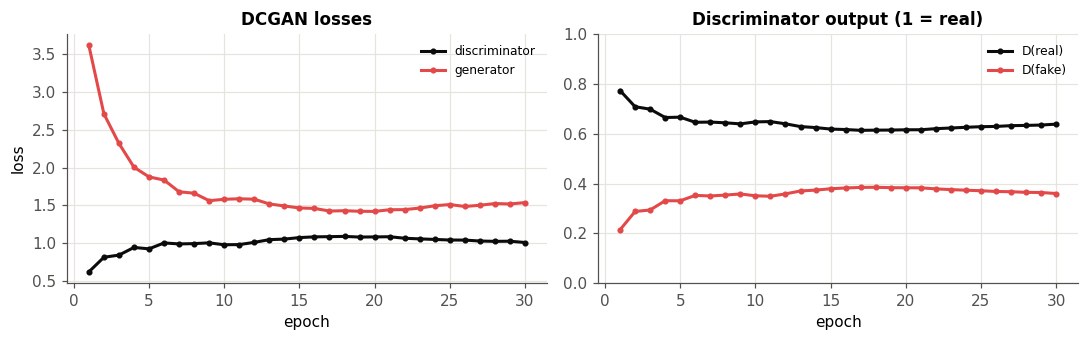

In [29]:
def train_dcgan():
    # Train the conditional DCGAN, resuming from the last saved epoch if there is one.
    ckpt_path = GAN_MODEL_DIR / "dcgan.pt"
    seed_everything(SEED)
    G, D = Generator().to(device), Discriminator().to(device)
    G.apply(dcgan_init)
    D.apply(dcgan_init)
    opt_g = torch.optim.Adam(G.parameters(), lr=DCGAN_LR, betas=DCGAN_BETAS)
    opt_d = torch.optim.Adam(D.parameters(), lr=DCGAN_LR, betas=DCGAN_BETAS)
    history, start = [], 1
    if ckpt_path.exists():
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        for obj, key in ((G, "G"), (D, "D"), (opt_g, "opt_g"), (opt_d, "opt_d")):
            obj.load_state_dict(ckpt[key])
        history, start = ckpt["history"], ckpt["epoch"] + 1
        print(f"DCGAN checkpoint found (epoch {ckpt['epoch']})")

    steps = len(X_cifar) // DCGAN_BATCH
    for epoch in range(start, DCGAN_EPOCHS + 1):
        torch.manual_seed(SEED + epoch)               # a resumed run stays reproducible per epoch
        G.train()
        D.train()
        order = torch.randperm(len(X_cifar), device=device)
        sums, t0 = {}, time.time()
        for s in tqdm(range(steps), desc=f"DCGAN epoch {epoch}/{DCGAN_EPOCHS}", leave=False):
            x, y = real_batch(X_cifar, Y_cifar, order[s * DCGAN_BATCH:(s + 1) * DCGAN_BATCH])
            for k, v in gan_step(G, D, opt_g, opt_d, x, y).items():
                sums[k] = sums.get(k, 0.0) + v
        row = {"epoch": epoch, **{k: v / steps for k, v in sums.items() if k != "extra_loss"},
               "epoch_time_s": time.time() - t0}
        history.append(row)
        print(f"  epoch {epoch}: D loss {row['d_loss']:.3f} | G loss {row['g_loss']:.3f} | "
              f"D(real) {row['D(real)']:.2f} | D(fake) {row['D(fake)']:.2f} | {row['epoch_time_s']:.0f}s")
        torch.save({"G": G.state_dict(), "D": D.state_dict(), "opt_g": opt_g.state_dict(),
                    "opt_d": opt_d.state_dict(), "epoch": epoch, "history": history}, ckpt_path)
    pd.DataFrame(history).to_csv(RESULTS_DIR / "05_dcgan_training_history.csv", index=False)
    return G.eval(), D.eval(), pd.DataFrame(history)


G_dc, D_dc, dcgan_history = train_dcgan()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(dcgan_history.epoch, dcgan_history.d_loss, "-o", color=INK, markersize=3, label="discriminator")
axes[0].plot(dcgan_history.epoch, dcgan_history.g_loss, "-o", color="#e34948", markersize=3, label="generator")
axes[0].set(title="DCGAN losses", xlabel="epoch", ylabel="loss")
axes[0].legend(fontsize=8)
axes[1].plot(dcgan_history.epoch, dcgan_history["D(real)"], "-o", color=INK, markersize=3, label="D(real)")
axes[1].plot(dcgan_history.epoch, dcgan_history["D(fake)"], "-o", color="#e34948", markersize=3, label="D(fake)")
axes[1].set(title="Discriminator output (1 = real)", xlabel="epoch", ylim=(0, 1))
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_dcgan_training.png")
plt.show()

**What this shows.** Training stayed stable for all 30 epochs: D(real) stayed near 0.64 and D(fake) near 0.36, so neither network overpowered the other and there was no sign of mode collapse. Each epoch took about 26 seconds on the T4.

## 3 · Loading the pretrained StyleGAN2-ADA

StyleGAN2-ADA (Karras et al., 2020) is one of the strongest GANs for CIFAR-10. NVIDIA released a class-conditional CIFAR-10 model, which is loaded here with the official `stylegan3` code (that code can also read StyleGAN2-ADA checkpoints). The model and code are released under the NVIDIA Source Code License for non-commercial research use, which covers this study.

StyleGAN's custom CUDA kernels need to be compiled, and that often fails on Colab. The code uses the library's reference PyTorch versions of the two operations instead. They give the same output and are fast enough at 32×32. If the model can't be loaded for any reason, the notebook says so and carries on with the DCGAN only.

In [30]:
SG_REPO = Path("/content/stylegan3")
SG_URL = "https://nvlabs-fi-cdn.nvidia.com/stylegan2-ada-pytorch/pretrained/cifar10.pkl"
SG_PKL = GAN_MODEL_DIR / "stylegan2-ada_cifar10.pkl"

G_sg, sg_error = None, None
try:
    if not SG_REPO.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/NVlabs/stylegan3.git",
                        str(SG_REPO)], check=True)
    if not SG_PKL.exists():
        torch.hub.download_url_to_file(SG_URL, str(SG_PKL))
    try:                                   # older StyleGAN code imports pkg_resources,
        import pkg_resources               # which newer Python setups no longer ship
    except ImportError:
        from packaging.version import parse as _parse_version
        shim = types.ModuleType("pkg_resources")
        shim.parse_version = _parse_version
        sys.modules["pkg_resources"] = shim
    if str(SG_REPO) not in sys.path:
        sys.path.insert(0, str(SG_REPO))
    import legacy
    from torch_utils.ops import bias_act, upfirdn2d
    bias_act._init = lambda: False         # use the reference PyTorch ops, no CUDA compilation
    upfirdn2d._init = lambda: False
    with open(SG_PKL, "rb") as f:
        G_sg = legacy.load_network_pkl(f)["G_ema"].to(device).eval()
    print(f"StyleGAN2-ADA loaded: {G_sg.img_resolution}x{G_sg.img_resolution} images, "
          f"{G_sg.c_dim} classes, latent size {G_sg.z_dim}")
except Exception as e:
    sg_error = repr(e)
    print("StyleGAN2-ADA could not be loaded, continuing with the DCGAN only:", sg_error)

StyleGAN2-ADA loaded: 32x32 images, 10 classes, latent size 512


## 4 · GAN test sets

Each GAN produces 10,000 fakes, 1,000 per class, from fixed latent vectors (seed 2027). Two test sets are built per GAN:

- **clean:** the fakes saved as JPEG with the dataset's settings;
- **blurred:** the fakes blurred with a Gaussian of radius 2 px before saving. This is the same strength as Jiang's blurred SD 2.1 set (notebook 01), so it repeats his evasion attack on GAN fakes.

As in all other test sets, the real half is the same 10,000 CIFAR-10 test photographs. The SHA-1 check from notebook 01 removes any fake that is pixel-identical to a training, validation or real test image.

In [31]:
@torch.no_grad()
def generate(forward, z_dim, classes=FAKE_CLASSES, seed=GEN_SEED, batch=500):
    # Images for the given classes from fixed latent vectors; forward(z, y) returns NCHW in [-1, 1]
    g = torch.Generator(device=device).manual_seed(seed)
    out = []
    for i in range(0, len(classes), batch):
        y = torch.as_tensor(classes[i:i + batch], device=device)
        z = torch.randn(len(y), z_dim, device=device, generator=g)
        out.append(to_uint8(forward(z, y)))
    return np.concatenate(out)


def cached_raw(name, forward, z_dim):
    # Generated images before JPEG, cached in Drive
    path = GAN_DATA_DIR / f"{name}_raw.npz"
    if path.exists():
        with np.load(path) as z:
            return z["x"]
    x = generate(forward, z_dim)
    np.savez(path, x=x, c=FAKE_CLASSES)
    return x


def build_test_set(name, fakes, classes):
    # Real test photographs + fakes, leakage-checked, shuffled and saved like notebook 01's splits
    path = GAN_DATA_DIR / f"{name}.npz"
    if path.exists():
        with np.load(path) as z:
            return z["x"], z["y"], z["c"]
    h = sha1s(fakes)
    leaked = np.isin(h, list(seen_hashes | real_hashes))
    dup = pd.Series(h).duplicated().to_numpy()
    keep = ~leaked & ~dup
    print(f"{name}: {leaked.sum()} fakes identical to training/real images removed, "
          f"{dup.sum()} exact duplicates removed")
    x = np.concatenate([real_test, fakes[keep]])
    y = np.concatenate([np.full(len(real_test), REAL), np.full(keep.sum(), FAKE)]).astype(np.int64)
    c = np.concatenate([np.full(len(real_test), -1), classes[keep]])
    order = np.random.default_rng(SEED).permutation(len(y))
    x, y, c = x[order], y[order], c[order]
    np.savez(path, x=x, y=y, c=c)
    return x, y, c


GENERATORS = {"dcgan": ("DCGAN", lambda z, y: G_dc(z, y), Z_DIM)}
if G_sg is not None:
    GENERATORS["stylegan2"] = ("StyleGAN2-ADA",
                               lambda z, y: G_sg(z, F.one_hot(y, G_sg.c_dim).float(),
                                                 truncation_psi=1.0, noise_mode="const"),
                               G_sg.z_dim)

GAN_TEST_SETS, test_sets, test_classes, raw_fakes = {}, {}, {}, {}
for key, (label, forward, z_dim) in GENERATORS.items():
    raw_fakes[key] = cached_raw(key, forward, z_dim)
    for suffix, radius, tag in (("", 0, ""), ("_blur", BLUR_RADIUS, " blurred")):
        name = f"test_{key}{suffix}"
        x, y, c = build_test_set(name, jpeg_roundtrip(raw_fakes[key], radius), FAKE_CLASSES)
        GAN_TEST_SETS[name] = label + tag
        test_sets[name], test_classes[name] = (x, y), c

pd.DataFrame({name: pd.Series(y).map(LABEL_NAMES).value_counts() for name, (_, y) in test_sets.items()}).T

,FAKE,REAL
test_dcgan,10000,10000
test_dcgan_blur,10000,10000
test_stylegan2,10000,10000
test_stylegan2_blur,10000,10000


In [ ]:
# Sample images: real photographs, the two GANs (one column per class) and SD 2.1 fakes for comparison
x21, y21 = load_split("test_sd21")
rng = np.random.default_rng(SEED)
rows = [("Real (CIFAR-10)", real_test[rng.choice(len(real_test), 10, replace=False)])]
for key, (label, _, _) in GENERATORS.items():
    x, y = test_sets[f"test_{key}"]
    c = test_classes[f"test_{key}"]
    rows.append((label, np.stack([x[np.flatnonzero((y == FAKE) & (c == k))[0]] for k in range(10)])))
rows.append(("SD 2.1", x21[y21 == FAKE][rng.choice((y21 == FAKE).sum(), 10, replace=False)]))
x, y = test_sets["test_dcgan_blur"]
rows.append(("DCGAN blurred", x[y == FAKE][:10]))

fig, axes = plt.subplots(len(rows), 1, figsize=(10, 1.25 * len(rows)))
for ax, (label, imgs) in zip(axes, rows):
    strip = np.concatenate([np.pad(i, ((1, 1), (1, 1), (0, 0)), constant_values=255) for i in imgs], axis=1)
    ax.imshow(strip, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_ylabel(label, rotation=0, ha="right", va="center")
axes[0].set_title("GAN rows show one image per class: " + ", ".join(CIFAR10_CLASSES), fontsize=9)
fig.savefig(FIG_DIR / "05_gan_samples.png")
plt.show()

**What this shows.** Each GAN test set has 10,000 real photographs and 10,000 fakes (1,000 per class). The SHA-1 check removed nothing, so no GAN fake is a copy of a training or test image.

## 5 · How realistic are the GAN images? (FID)

The Fréchet Inception Distance (FID; Heusel et al., 2017) compares the Inception-v3 feature statistics of generated images with those of real images. Lower means more realistic. Each set of 10,000 fakes is compared with the 10,000 real test photographs, after the same JPEG step, so all generators (GANs and Stable Diffusion) are measured the same way. FID on 10,000 images is higher than the usual 50,000-image figures in GAN papers, so these numbers should only be compared with each other.

In [33]:
from torchmetrics.image.fid import FrechetInceptionDistance

FID_FILE = RESULTS_DIR / "05_fid.csv"
fid_metric = None


def fid_against_real(fakes, batch=500):
    # FID-10k between the given fakes and the real test photographs
    global fid_metric
    if fid_metric is None:
        fid_metric = FrechetInceptionDistance(feature=2048, reset_real_features=False).to(device)
        for i in range(0, len(real_test), batch):
            fid_metric.update(torch.from_numpy(real_test[i:i + batch]).permute(0, 3, 1, 2).to(device), real=True)
    fid_metric.reset()                     # keeps the real statistics, clears the fakes
    for i in range(0, len(fakes), batch):
        fid_metric.update(torch.from_numpy(fakes[i:i + batch]).permute(0, 3, 1, 2).to(device), real=False)
    return float(fid_metric.compute())


fid_table = pd.read_csv(FID_FILE) if FID_FILE.exists() else pd.DataFrame(columns=["generator", "fid_10k"])
fid_sources = {label: test_sets[f"test_{key}"] for key, (label, _, _) in GENERATORS.items()}
fid_sources.update({SD_TEST_SETS[t]: load_split(t) for t in ("test_sd14", "test_sd21", "test_sd30")})
for label, (x, y) in fid_sources.items():
    if label not in set(fid_table.generator):
        fid_table.loc[len(fid_table)] = [label, fid_against_real(x[y == FAKE])]
        fid_table.to_csv(FID_FILE, index=False)
fid_table.round(2)

,generator,fid_10k
0,DCGAN,29.36
1,StyleGAN2-ADA,6.15
2,SD 1.4,31.40
3,SD 2.1,40.77
4,SD 3.0,36.40
5,DCGAN fine-tuned against ResNet-50 (CNN),36.88
6,DCGAN fine-tuned against ViT-S/16 (Transformer),33.35


**What this shows.** StyleGAN2-ADA (FID 6.1) is far more realistic than every Stable Diffusion set (31.4 to 40.8), while our DCGAN (29.4) is about as realistic as SD 1.4. The adversarial fine-tuning made the DCGAN images slightly less realistic (33.3 and 36.9).

## 6 · Detector accuracy on GAN fakes

All 16 detectors are evaluated on every GAN test set with the same metrics as notebook 03. The table puts the GAN results next to the diffusion results from notebook 03, so each model can be compared across both families of generator.

In [39]:
all_models = {run: load_detector(run[0], run[1], run[2], run[3]) for run in available_runs}
names = {k: v["display_name"] for k, v in MODELS.items()}
cnn, vit = list(MODELS)
print(f"{len(all_models)} detectors loaded")


def cached_predictions(run, tname):
    # Same cache naming as notebook 03, so all predictions sit in one folder
    f = PRED_DIR / f"{run_name(*run)}__{tname}.npy"
    x = test_sets[tname][0]
    if f.exists():
        p = np.load(f)
        if len(p) == len(x):
            return p
    p = predict_proba(all_models[run], x)
    np.save(f, p)
    return p


P, rows = {}, []
for run in tqdm(available_runs, desc="Evaluating detectors"):
    setup, m, seed, aug = run
    for tname, (x, y) in test_sets.items():
        P[(run, tname)] = p = cached_predictions(run, tname)
        rows.append({"setup": setup, "model": m, "seed": seed, "augment": aug, "test_set": tname,
                     **compute_metrics(y, p)})
gan_metrics_all = pd.DataFrame(rows)
gan_metrics_all.to_csv(RESULTS_DIR / "05_metrics_all_runs.csv", index=False)

KEY = ["accuracy", "fake_acc", "real_acc", "f1_fake", "auroc", "false_accusation_rate"]
main_runs = gan_metrics_all[~gan_metrics_all.augment]
grouped = main_runs.groupby(["setup", "model", "test_set"], sort=False)
gan_mean, gan_std = grouped[KEY].mean().reset_index(), grouped[KEY].std().reset_index()
gan_mean["n_seeds"] = grouped.size().values
gan_mean.to_csv(RESULTS_DIR / "05_metrics_mean_across_seeds.csv", index=False)
gan_std.to_csv(RESULTS_DIR / "05_metrics_std_across_seeds.csv", index=False)

# Diffusion results from notebook 03 + GAN results, in one table (accuracy ± SD, AUROC in brackets)
sd_mean = pd.read_csv(RESULTS_DIR / "metrics_mean_across_seeds.csv")
sd_std = pd.read_csv(RESULTS_DIR / "metrics_std_across_seeds.csv")
both_mean = pd.concat([sd_mean, gan_mean], ignore_index=True)
both_std = pd.concat([sd_std, gan_std], ignore_index=True)
ALL_TEST_SETS = {**SD_TEST_SETS, **GAN_TEST_SETS}


def cell_text(setup, m, t, col="accuracy"):
    sel = lambda d: d[(d.setup == setup) & (d.model == m) & (d.test_set == t)]
    a, s, auc = sel(both_mean)[col].item(), sel(both_std)[col].item(), sel(both_mean).auroc.item()
    return f"{a:.1f} ± {s:.1f} ({auc:.1f})"


combined = pd.DataFrame([{"trained on": s.replace("train", ""), "model": names[m],
                          **{ALL_TEST_SETS[t]: cell_text(s, m, t) for t in ALL_TEST_SETS},
                          "false accusations (%)": round(sd_mean[(sd_mean.setup == s) & (sd_mean.model == m)]
                                                         .false_accusation_rate.iloc[0], 2)}
                         for s in TRAIN_SETUPS for m in MODELS])
combined.to_csv(RESULTS_DIR / "05_combined_accuracy_table.csv", index=False)
combined.set_index(["trained on", "model"])

16 detectors loaded


Evaluating detectors:   0%|          | 0/16 [00:00<?, ?it/s]

SD 1.4              SD 2.1  \
trained on model                                                           
SD14       ResNet-50 (CNN)         95.2 ± 0.0 (99.0)   93.4 ± 0.1 (98.3)   
           ViT-S/16 (Transformer)  97.9 ± 0.8 (99.8)   95.5 ± 0.3 (99.4)   
SD21       ResNet-50 (CNN)         81.0 ± 1.0 (94.8)   97.5 ± 0.1 (99.7)   
           ViT-S/16 (Transformer)  83.0 ± 1.6 (98.0)  99.2 ± 0.1 (100.0)   

                                              SD 3.0     SD 2.1 blurred  \
trained on model                                                          
SD14       ResNet-50 (CNN)         90.1 ± 0.3 (97.2)  87.7 ± 3.8 (96.4)   
           ViT-S/16 (Transformer)  89.4 ± 1.8 (98.2)  55.5 ± 5.3 (91.1)   
SD21       ResNet-50 (CNN)         75.3 ± 1.0 (90.2)  88.6 ± 3.1 (98.1)   
           ViT-S/16 (Transformer)  71.3 ± 1.5 (94.2)  62.3 ± 8.8 (97.5)   

                                               DCGAN      DCGAN blurred  \
trained on model                                                          
SD14       ResNet-50 (CNN)         48.4 ± 0.1 (43.2)  77.2 ± 2.7 (93.4)   
           ViT-S/16 (Transformer)  49.1 ± 0.2 (30.1)  49.8 ± 1.1 (85.8)   
SD21       ResNet-50 (CNN)         49.2 ± 0.1 (46.2)  72.7 ± 2.8 (95.2)   
           ViT-S/16 (Transformer)  50.0 ± 0.1 (39.6)  50.6 ± 1.0 (93.5)   

                                       StyleGAN2-ADA StyleGAN2-ADA blurred  \
trained on model                                                             
SD14       ResNet-50 (CNN)         50.8 ± 0.1 (54.2)     78.8 ± 4.3 (93.5)   
           ViT-S/16 (Transformer)  50.2 ± 0.1 (52.2)     51.1 ± 2.3 (87.5)   
SD21       ResNet-50 (CNN)         50.0 ± 0.0 (51.0)     70.9 ± 4.1 (94.3)   
           ViT-S/16 (Transformer)  50.1 ± 0.0 (49.7)     50.8 ± 1.2 (93.0)   

                                   false accusations (%)  
trained on model                                          
SD14       ResNet-50 (CNN)                          5.06  
           ViT-S/16 (Transformer)                   1.97  
SD21       ResNet-50 (CNN)                          2.53  
           ViT-S/16 (Transformer)                   0.68

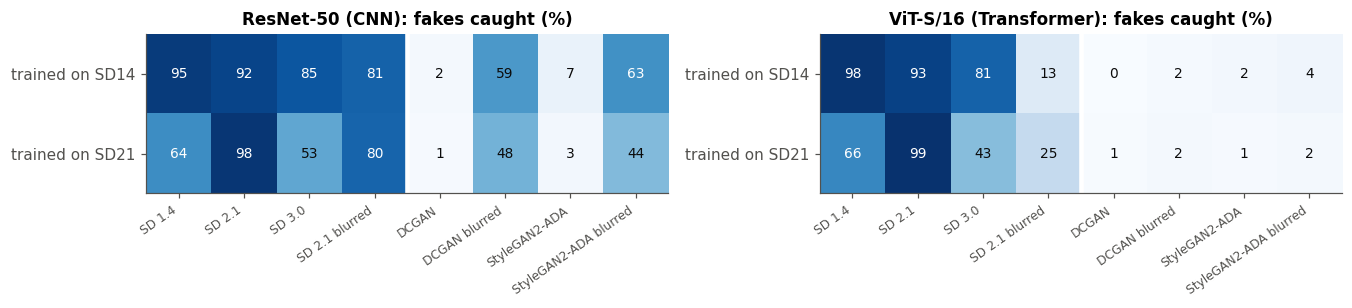

acc_main  acc_augmented  \
setup     model                  test_set                                       
trainSD14 ResNet-50 (CNN)        test_dcgan              48.42          47.60   
                                 test_dcgan_blur         77.16          50.68   
                                 test_stylegan2          50.85          50.62   
                                 test_stylegan2_blur     78.81          53.98   
          ViT-S/16 (Transformer) test_dcgan              49.12          48.77   
                                 test_dcgan_blur         49.76          50.27   
                                 test_stylegan2          50.20          49.98   
                                 test_stylegan2_blur     51.10          52.35   
trainSD21 ResNet-50 (CNN)        test_dcgan              49.18          48.36   
                                 test_dcgan_blur         72.72          50.71   
                                 test_stylegan2          50.05          49.78   
                                 test_stylegan2_blur     70.88          52.16   
          ViT-S/16 (Transformer) test_dcgan              49.99          49.97   
                                 test_dcgan_blur         50.55          51.61   
                                 test_stylegan2          50.10          49.96   
                                 test_stylegan2_blur     50.76          51.58   

                                                      change  fake_acc_main  \
setup     model                  test_set                                     
trainSD14 ResNet-50 (CNN)        test_dcgan            -0.82           1.90   
                                 test_dcgan_blur      -26.48          59.38   
                                 test_stylegan2        -0.22           6.75   
                                 test_stylegan2_blur  -24.83          62.67   
          ViT-S/16 (Transformer) test_dcgan            -0.35           0.21   
                                 test_dcgan_blur        0.51           1.50   
                                 test_stylegan2        -0.22           2.37   
                                 test_stylegan2_blur    1.25           4.17   
trainSD21 ResNet-50 (CNN)        test_dcgan            -0.83           0.89   
                                 test_dcgan_blur      -22.01          47.97   
                                 test_stylegan2        -0.26           2.62   
                                 test_stylegan2_blur  -18.72          44.28   
          ViT-S/16 (Transformer) test_dcgan            -0.02           0.67   
                                 test_dcgan_blur        1.06           1.78   
                                 test_stylegan2        -0.15           0.89   
                                 test_stylegan2_blur    0.82           2.20   

                                                      fake_acc_augmented  \
setup     model                  test_set                                  
trainSD14 ResNet-50 (CNN)        test_dcgan                         2.89   
                                 test_dcgan_blur                    9.05   
                                 test_stylegan2                     8.94   
                                 test_stylegan2_blur               15.65   
          ViT-S/16 (Transformer) test_dcgan                         0.31   
                                 test_dcgan_blur                    3.31   
                                 test_stylegan2                     2.72   
                                 test_stylegan2_blur                7.47   
trainSD21 ResNet-50 (CNN)        test_dcgan                         1.65   
                                 test_dcgan_blur                    6.36   
                                 test_stylegan2                     4.51   
                                 test_stylegan2_blur                9.26   
          ViT-S/16 (Transformer) test_dcgan                         0.91   
                                

In [40]:
# Fake-image accuracy (share of fakes caught) on every test set, mean of the three seeds
fig, axes = plt.subplots(1, len(MODELS), figsize=(6.2 * len(MODELS), 2.9), squeeze=False)
cols = list(ALL_TEST_SETS)
for ax, m in zip(axes[0], MODELS):
    t = both_mean[both_mean.model == m].pivot(index="setup", columns="test_set", values="fake_acc")[cols]
    ax.imshow(t.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(len(cols)), [ALL_TEST_SETS[c] for c in cols], rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(t)), [s.replace("train", "trained on ") for s in t.index])
    ax.axvline(len(SD_TEST_SETS) - 0.5, color="white", lw=3)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 60 else INK)
    ax.set_title(f"{names[m]}: fakes caught (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_fake_accuracy_heatmap.png")
plt.show()

# Blur/JPEG-augmented models (seed 42) against the mean of the three main models
rows = []
for (setup, m, seed, aug) in [r for r in available_runs if r[3]]:
    for t in GAN_TEST_SETS:
        a = gan_metrics_all[(gan_metrics_all.setup == setup) & (gan_metrics_all.model == m)
                            & gan_metrics_all.augment & (gan_metrics_all.test_set == t)].iloc[0]
        b = gan_mean[(gan_mean.setup == setup) & (gan_mean.model == m) & (gan_mean.test_set == t)].iloc[0]
        rows.append({"setup": setup, "model": m, "test_set": t, "acc_main": b.accuracy,
                     "acc_augmented": a.accuracy, "change": a.accuracy - b.accuracy,
                     "fake_acc_main": b.fake_acc, "fake_acc_augmented": a.fake_acc,
                     "auroc_main": b.auroc, "auroc_augmented": a.auroc})
gan_augmentation = pd.DataFrame(rows)
gan_augmentation.to_csv(RESULTS_DIR / "05_augmentation_effect.csv", index=False)
gan_augmentation.assign(model=gan_augmentation.model.map(names)).set_index(["setup", "model", "test_set"]).round(2)

**What this shows.** Every detector is at chance on clean GAN fakes: accuracy is 48 to 51% and they catch at most 6.8% of the fakes. On DCGAN the AUROC is even below 50, so the models rate GAN fakes as more real than the real photographs. Blurring the fakes makes the CNN catch about half of them, but the next sections show that this is the blur being detected, not the GAN.

## 7 · Statistical significance (McNemar's test)

The test is the same as in notebook 03. For each seed, the CNN and the ViT are compared on the same images, counting only the images where exactly one of them is correct. A difference only counts as robust if it points the same way in all three seeds.

In [41]:
rows = []
for setup in TRAIN_SETUPS:
    for seed in SEEDS:
        rc, rv = (setup, cnn, seed, False), (setup, vit, seed, False)
        if rc not in all_models or rv not in all_models:
            continue
        for tname, (_, y) in test_sets.items():
            cnn_ok, vit_ok = (P[(rc, tname)] >= 0.5) == y, (P[(rv, tname)] >= 0.5) == y
            only_cnn, only_vit = int((cnn_ok & ~vit_ok).sum()), int((~cnn_ok & vit_ok).sum())
            n = only_cnn + only_vit
            p_value = binomtest(only_cnn, n, 0.5).pvalue if n else 1.0
            rows.append({"setup": setup, "seed": seed, "test_set": tname, "only CNN correct": only_cnn,
                         "only ViT correct": only_vit, "p_value": p_value,
                         "better model": "ViT" if only_vit > only_cnn else "CNN",
                         "significant (p < 0.05)": p_value < 0.05})
gan_significance = pd.DataFrame(rows)
gan_significance.to_csv(RESULTS_DIR / "05_significance_mcnemar_all_seeds.csv", index=False)
gan_consistency = (gan_significance.groupby(["setup", "test_set"], sort=False)
                   .agg(seeds=("seed", "count"),
                        ViT_better_in=("better model", lambda w: int((w == "ViT").sum())),
                        significant_in=("significant (p < 0.05)", "sum"),
                        largest_p=("p_value", "max")))
gan_consistency.to_csv(RESULTS_DIR / "05_significance_consistency.csv")
gan_consistency

seeds  ViT_better_in  significant_in  \
setup     test_set                                                    
trainSD14 test_dcgan               3              3               3   
          test_dcgan_blur          3              0               3   
          test_stylegan2           3              0               3   
          test_stylegan2_blur      3              0               3   
trainSD21 test_dcgan               3              3               3   
          test_dcgan_blur          3              0               3   
          test_stylegan2           3              2               0   
          test_stylegan2_blur      3              0               3   

                                  largest_p  
setup     test_set                           
trainSD14 test_dcgan           4.500534e-06  
          test_dcgan_blur      0.000000e+00  
          test_stylegan2       8.273315e-05  
          test_stylegan2_blur  0.000000e+00  
trainSD21 test_dcgan           6.065764e-15  
          test_dcgan_blur      0.000000e+00  
          test_stylegan2       7.488756e-01  
          test_stylegan2_blur  0.000000e+00

**What this shows.** McNemar's test finds the two models different in every seed for seven of the eight comparisons (not for StyleGAN2-ADA after SD 2.1 training). With both models near 50% accuracy, these differences have no practical meaning.

## 8 · Threshold recalibration on GAN fakes

In notebook 03, most of the ViT's errors on new diffusion generators came from the 0.5 cut-off being in the wrong place, not from the model losing the real-vs-fake signal. The same protocol tests whether this also holds for GANs. A cut-off is chosen on 100 real and 100 fake labelled images from each GAN test set, then accuracy is measured on the remaining images. The calibration images are the same for every model.

In [42]:
CALIB_PER_CLASS = 100
THRESHOLDS = np.unique(np.concatenate([np.logspace(-4, np.log10(0.5), 80),
                                       1 - np.logspace(np.log10(0.5), -4, 80)]))


def best_threshold(p, y):
    # Cut-off with the highest accuracy on the calibration sample (ties: closest to 0.5)
    accs = np.array([((p >= t) == y).mean() for t in THRESHOLDS])
    best = np.flatnonzero(accs == accs.max())
    return THRESHOLDS[best[np.argmin(np.abs(THRESHOLDS[best] - 0.5))]]


rows = []
for i, (tname, (_, y)) in enumerate(test_sets.items()):
    cal_rng = np.random.default_rng(SEED + len(SD_TEST_SETS) + i)   # continues notebook 03's seeds
    cal = np.concatenate([cal_rng.choice(np.flatnonzero(y == lab), CALIB_PER_CLASS, replace=False)
                          for lab in (REAL, FAKE)])
    rest = np.setdiff1d(np.arange(len(y)), cal)
    for run in available_runs:
        setup, m, seed, aug = run
        p = P[(run, tname)]
        t = best_threshold(p[cal], y[cal])
        row = {"setup": setup, "model": m, "seed": seed, "augment": aug, "test_set": tname, "threshold": t}
        for kind, cut in (("default", 0.5), ("recalibrated", t)):
            pred = p[rest] >= cut
            row[f"acc_{kind}"] = (pred == y[rest]).mean() * 100
            row[f"fake_acc_{kind}"] = pred[y[rest] == FAKE].mean() * 100
            row[f"real_acc_{kind}"] = (~pred[y[rest] == REAL]).mean() * 100
        rows.append(row)
gan_recal_all = pd.DataFrame(rows)
gan_recal_all["gain"] = gan_recal_all.acc_recalibrated - gan_recal_all.acc_default
gan_recal_all.to_csv(RESULTS_DIR / "05_threshold_recalibration_all_runs.csv", index=False)
gan_recal = (gan_recal_all[~gan_recal_all.augment]
             .groupby(["setup", "model", "test_set"], sort=False)
             [["threshold", "acc_default", "acc_recalibrated", "gain", "fake_acc_recalibrated",
               "real_acc_recalibrated"]].mean().reset_index())
gan_recal.to_csv(RESULTS_DIR / "05_threshold_recalibration.csv", index=False)
gan_recal.assign(model=gan_recal.model.map(names)).set_index(["setup", "model", "test_set"]).round(2)

threshold  acc_default  \
setup     model                  test_set                                      
trainSD14 ResNet-50 (CNN)        test_dcgan                0.31        48.41   
          ViT-S/16 (Transformer) test_dcgan                0.57        49.11   
trainSD21 ResNet-50 (CNN)        test_dcgan                0.05        49.17   
          ViT-S/16 (Transformer) test_dcgan                0.22        49.98   
trainSD14 ResNet-50 (CNN)        test_dcgan_blur           0.15        77.17   
          ViT-S/16 (Transformer) test_dcgan_blur           0.00        49.76   
trainSD21 ResNet-50 (CNN)        test_dcgan_blur           0.06        72.75   
          ViT-S/16 (Transformer) test_dcgan_blur           0.00        50.55   
trainSD14 ResNet-50 (CNN)        test_stylegan2            0.02        50.84   
          ViT-S/16 (Transformer) test_stylegan2            0.04        50.18   
trainSD21 ResNet-50 (CNN)        test_stylegan2            0.01        50.05   
          ViT-S/16 (Transformer) test_stylegan2            0.01        50.10   
trainSD14 ResNet-50 (CNN)        test_stylegan2_blur       0.15        78.81   
          ViT-S/16 (Transformer) test_stylegan2_blur       0.00        51.09   
trainSD21 ResNet-50 (CNN)        test_stylegan2_blur       0.05        70.90   
          ViT-S/16 (Transformer) test_stylegan2_blur       0.00        50.75   

                                                      acc_recalibrated   gain  \
setup     model                  test_set                                       
trainSD14 ResNet-50 (CNN)        test_dcgan                      48.76   0.35   
          ViT-S/16 (Transformer) test_dcgan                      49.09  -0.02   
trainSD21 ResNet-50 (CNN)        test_dcgan                      47.81  -1.36   
          ViT-S/16 (Transformer) test_dcgan                      49.92  -0.06   
trainSD14 ResNet-50 (CNN)        test_dcgan_blur                 87.63  10.46   
          ViT-S/16 (Transformer) test_dcgan_blur                 78.34  28.57   
trainSD21 ResNet-50 (CNN)        test_dcgan_blur                 89.32  16.57   
          ViT-S/16 (Transformer) test_dcgan_blur                 84.59  34.03   
trainSD14 ResNet-50 (CNN)        test_stylegan2                  52.73   1.90   
          ViT-S/16 (Transformer) test_stylegan2                  51.14   0.96   
trainSD21 ResNet-50 (CNN)        test_stylegan2                  50.49   0.44   
          ViT-S/16 (Transformer) test_stylegan2                  50.13   0.04   
trainSD14 ResNet-50 (CNN)        test_stylegan2_blur             88.12   9.31   
          ViT-S/16 (Transformer) test_stylegan2_blur             81.01  29.92   
trainSD21 ResNet-50 (CNN)        test_stylegan2_blur             88.06  17.16   
          ViT-S/16 (Transformer) test_stylegan2_blur             83.34  32.59   

                                                      fake_acc_recalibrated  \
setup     model                  test_set                                     
trainSD14 ResNet-50 (CNN)        test_dcgan                           33.99   
          ViT-S/16 (Transformer) test_dcgan                            0.23   
trainSD21 ResNet-50 (CNN)        test_dcgan                            7.12   
          ViT-S/16 (Transformer) test_dcgan                            1.50   
trainSD14 ResNet-50 (CNN)        test_dcgan_blur                      87.26   
          ViT-S/16 (Transformer) test_dcgan_blur                      76.43   
trainSD21 ResNet-50 (CNN)        test_dcgan_blur                      87.53   
          ViT-S/16 (Transformer) test_dcgan_blur                      77.82   
trainSD14 ResNet-50 (CNN)        test_stylegan2                       41.73   
          ViT-S/16 (Transformer) test_stylegan2                       16.75   
trainSD21 ResNet-50 (CNN)        test_stylegan2                       31.50   
          ViT-S/16 (Transformer) test_stylegan2                        3.61   
trainSD14 ResNet-50 (CNN)        test_stylegan2_

**What this shows.** Recalibration cannot fix the clean GAN sets (47.8 to 52.7% after recalibration), because the signal is missing, not just the threshold. On the blurred sets it lifts accuracy to 78 to 89%, but only the fakes are blurred there, so the models are separating blurred from sharp images.

## 9 · Score distributions on GAN fakes

These are the P(fake) scores of the seed-42 models on real photographs and GAN fakes. If the fake scores still sit to the right of the real scores, the model can tell the two apart and only the cut-off is wrong. If they pile up near zero, the model is confidently wrong.

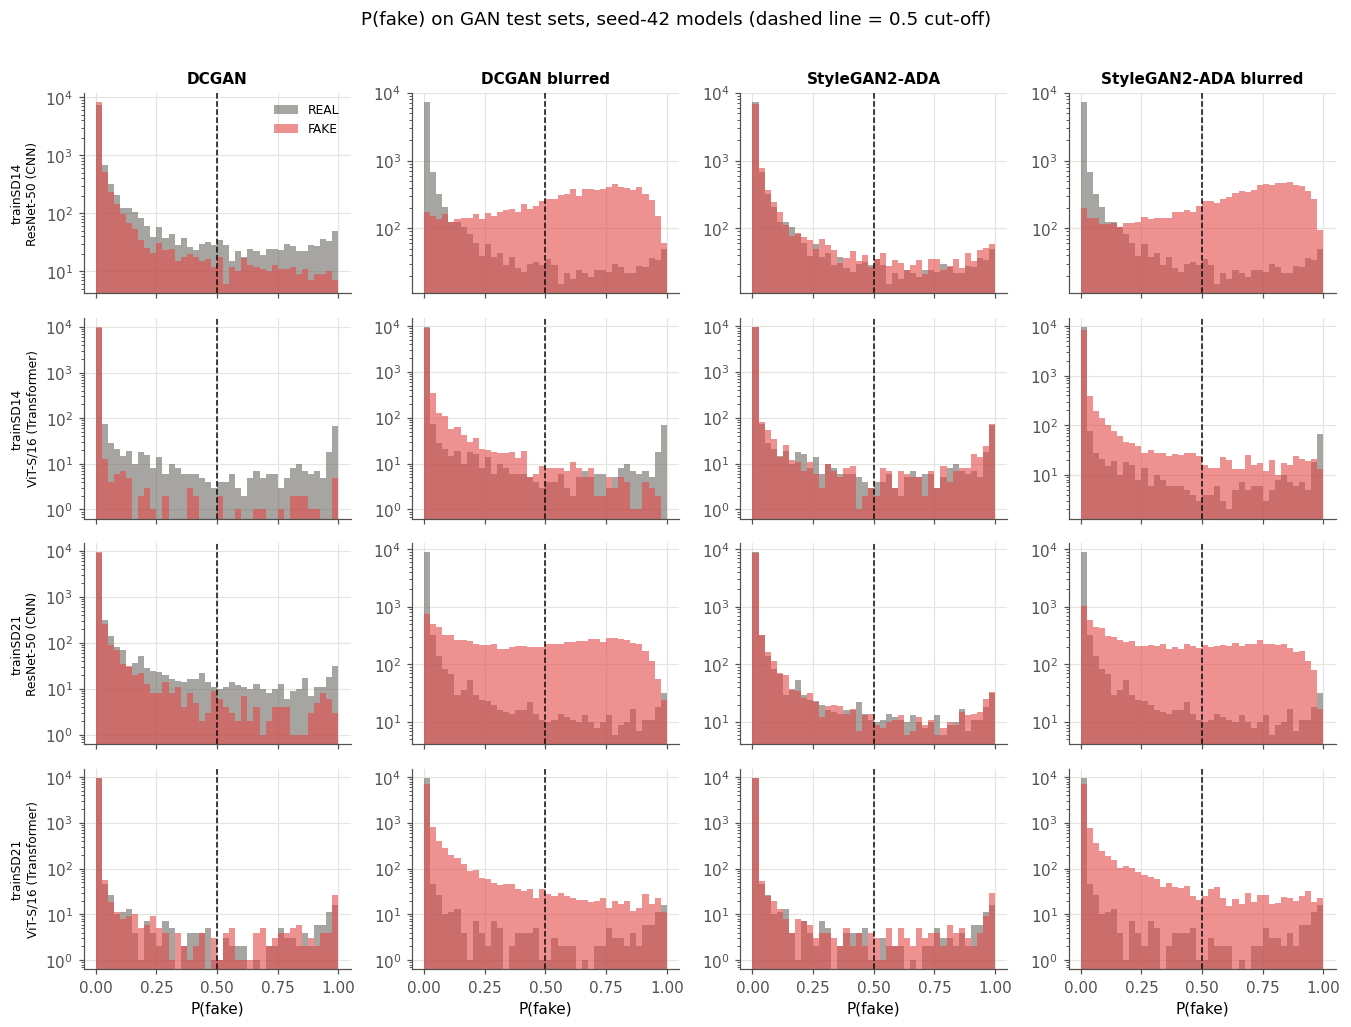

,setup,model,test_set,median P(fake) of fakes,% of fakes between 0.1 and 0.5,% of fakes below 0.1
0,trainSD14,ResNet-50 (CNN),test_dcgan,0.003,4.94,92.88
1,trainSD14,ResNet-50 (CNN),test_dcgan_blur,0.628,27.83,6.24
2,trainSD14,ResNet-50 (CNN),test_stylegan2,0.007,10.24,82.78
3,trainSD14,ResNet-50 (CNN),test_stylegan2_blur,0.679,23.43,5.98
4,trainSD14,ViT-S/16 (Transformer),test_dcgan,0.000,0.25,99.56
5,trainSD14,ViT-S/16 (Transformer),test_dcgan_blur,0.000,3.90,95.15
6,trainSD14,ViT-S/16 (Transformer),test_stylegan2,0.000,1.34,96.47
7,trainSD14,ViT-S/16 (Transformer),test_stylegan2_blur,0.001,6.37,90.19
8,trainSD21,ResNet-50 (CNN),test_dcgan,0.001,2.02,97.27
9,trainSD21,ResNet-50 (CNN),test_dcgan_blur,0.426,35.66,20.23


In [43]:
SCORE_COLORS = {REAL: "#6b6a63", FAKE: "#e34948"}
bins = np.linspace(0, 1, 41)
models42 = [(s, m) for s in TRAIN_SETUPS for m in MODELS if (s, m, 42, False) in all_models]
gan_names = list(GAN_TEST_SETS)

fig, axes = plt.subplots(len(models42), len(gan_names), figsize=(3.1 * len(gan_names), 2.3 * len(models42)),
                         sharex=True, squeeze=False)
rows = []
for r, (setup, m) in enumerate(models42):
    for c, tname in enumerate(gan_names):
        y, p = test_sets[tname][1], P[((setup, m, 42, False), tname)]
        ax = axes[r, c]
        for lab in (REAL, FAKE):
            ax.hist(p[y == lab], bins=bins, color=SCORE_COLORS[lab], alpha=0.6, label=LABEL_NAMES[lab])
        ax.axvline(0.5, color=INK, ls="--", lw=1)
        ax.set_yscale("log")
        if r == 0:
            ax.set_title(GAN_TEST_SETS[tname], fontsize=10)
        if c == 0:
            ax.set_ylabel(f"{setup}\n{names[m]}", fontsize=8)
        if r == len(models42) - 1:
            ax.set_xlabel("P(fake)")
        pf = p[y == FAKE]
        rows.append({"setup": setup, "model": names[m], "test_set": tname,
                     "median P(fake) of fakes": np.median(pf),
                     "% of fakes between 0.1 and 0.5": ((pf >= 0.1) & (pf < 0.5)).mean() * 100,
                     "% of fakes below 0.1": (pf < 0.1).mean() * 100})
axes[0, 0].legend(fontsize=8)
fig.suptitle("P(fake) on GAN test sets, seed-42 models (dashed line = 0.5 cut-off)", y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_score_distributions.png")
plt.show()
gan_scores = pd.DataFrame(rows)
gan_scores.to_csv(RESULTS_DIR / "05_score_summary.csv", index=False)
gan_scores.round(3)

**What this shows.** Most clean GAN fakes get a P(fake) below 0.1 (83 to 99.6% of them), so the models are confidently wrong, as the ViT was on blurred SD fakes in notebook 03.

## 10 · Blur applied to both real and GAN images

This is the controlled blur test from notebook 03, run on the GAN test sets. The blur is applied equally to real and fake images, as happens when images are re-shared. Solid lines are the seed-42 main models and dashed lines are the augmented models. A balanced subset of 4,000 images is used.

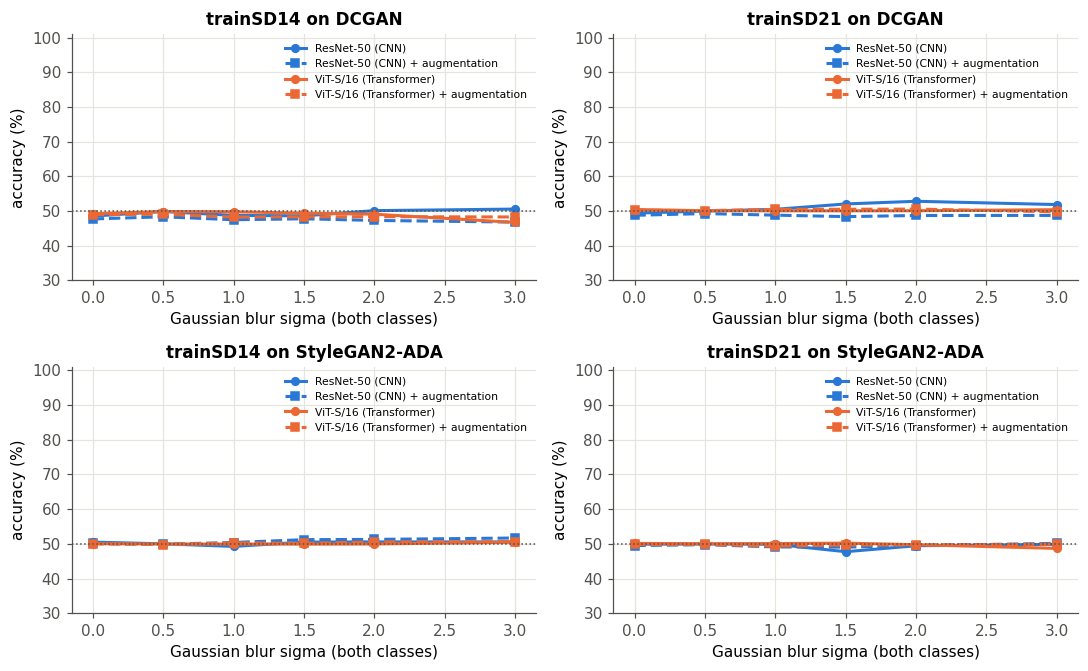

sigma                                        0.0   0.5   1.0   1.5   2.0   3.0
test_set       setup     model     augment                                    
test_dcgan     trainSD14 resnet50  False    48.6  49.9  48.8  48.6  50.1  50.6
                                   True     47.7  48.4  47.5  47.8  47.3  46.8
                         vit_small False    49.2  49.9  49.8  49.4  49.1  46.7
                                   True     49.0  49.1  48.3  48.3  48.4  48.3
               trainSD21 resnet50  False    49.4  50.0  50.5  52.0  52.8  51.9
                                   True     48.8  49.3  48.8  48.4  48.7  48.8
                         vit_small False    50.4  50.1  50.1  50.1  50.1  50.4
                                   True     50.2  50.1  50.5  50.5  50.6  49.8
test_stylegan2 trainSD14 resnet50  False    50.5  50.0  49.2  50.5  50.6  50.6
                                   True     50.1  49.9  50.4  51.2  51.3  51.7
                         vit_small False    50.0  50.0  50.0  49.9  50.0  50.5
                                   True     50.0  49.8  50.2  50.1  50.5  50.6
               trainSD21 resnet50  False    49.9  50.0  49.9  47.7  49.4  49.8
                                   True     49.5  49.8  49.1  49.0  49.5  50.1
                         vit_small False    50.1  50.0  50.1  50.2  49.8  48.7
                                   True     49.8  49.8  49.4  49.6  49.7  49.9

In [44]:
def blur(x, sigma):
    # Gaussian blur on uint8 NHWC images (same function as notebook 03)
    if sigma <= 0:
        return x
    k = 2 * int(np.ceil(3 * sigma)) + 1
    t = torch.from_numpy(x).permute(0, 3, 1, 2).float()
    t = gaussian_blur(t, kernel_size=[k, k], sigma=[sigma, sigma])
    return t.round().clamp(0, 255).byte().permute(0, 2, 3, 1).numpy()


sweep_sets = [f"test_{k}" for k in GENERATORS]
rng = np.random.default_rng(SEED)
rows = []
for tname in sweep_sets:
    x, y = test_sets[tname]
    idx = np.concatenate([rng.choice(np.flatnonzero(y == lab), ROBUSTNESS_IMAGES // 2, replace=False)
                          for lab in (REAL, FAKE)])
    x, y = x[idx], y[idx]
    for sigma in BLUR_SIGMAS:
        xb = blur(x, sigma)
        for run in [r for r in available_runs if r[2] == 42]:
            rows.append({"test_set": tname, "setup": run[0], "model": run[1], "augment": run[3],
                         "sigma": sigma, **compute_metrics(y, predict_proba(all_models[run], xb))})
gan_robustness = pd.DataFrame(rows)
gan_robustness.to_csv(RESULTS_DIR / "05_robustness_sweep.csv", index=False)

fig, axes = plt.subplots(len(sweep_sets), len(TRAIN_SETUPS), figsize=(10, 3.1 * len(sweep_sets)), squeeze=False)
for r, tname in enumerate(sweep_sets):
    for c, setup in enumerate(TRAIN_SETUPS):
        ax = axes[r, c]
        for m in MODELS:
            for aug, style in ((False, "-o"), (True, "--s")):
                g = gan_robustness[(gan_robustness.test_set == tname) & (gan_robustness.setup == setup)
                                   & (gan_robustness.model == m) & (gan_robustness.augment == aug)]
                if not g.empty:
                    ax.plot(g.sigma, g.accuracy, style, color=MODEL_COLORS[m], markersize=5,
                            label=names[m] + (" + augmentation" if aug else ""))
        ax.axhline(50, color=MUTED, lw=1, ls=":")
        ax.set(ylim=(30, 101), xlabel="Gaussian blur sigma (both classes)", ylabel="accuracy (%)",
               title=f"{setup} on {GAN_TEST_SETS[tname]}")
        ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_robustness.png")
plt.show()
gan_robustness.pivot_table(index=["test_set", "setup", "model", "augment"], columns="sigma",
                           values="accuracy").round(1)

**What this shows.** When the real photographs are blurred too, every model stays between 47 and 53% at every blur level. This confirms that the high scores on the blurred GAN sets came from the blur and not from GAN artefacts.

## 11 · GAN fingerprints in the frequency spectrum

Frank et al. (2020) showed that the upsampling layers of GANs leave regular patterns in the frequency spectrum. The figure shows each generator's average spectrum minus the real images' spectrum (same method as notebook 01). The line plot averages this difference over rings of equal frequency (an azimuthal average), so the generators can be compared on one axis, from low frequencies (left) to high (right).

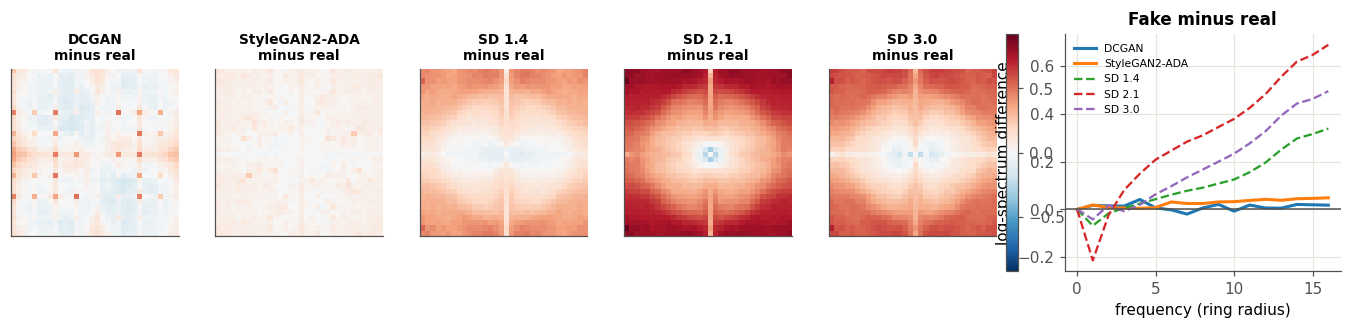

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
DCGAN,-0.000,0.017,0.015,0.014,0.042,0.006,-0.002,-0.020,0.006,0.021,-0.008,0.018,0.006,0.005,0.021,0.019,0.018
StyleGAN2-ADA,-0.000,0.018,0.008,0.006,0.004,0.008,0.031,0.025,0.024,0.031,0.032,0.038,0.042,0.038,0.045,0.046,0.048
SD 1.4,-0.000,-0.068,-0.017,0.006,0.024,0.043,0.062,0.078,0.091,0.108,0.125,0.156,0.196,0.250,0.297,0.316,0.338
SD 2.1,-0.000,-0.214,-0.025,0.081,0.150,0.208,0.246,0.284,0.310,0.345,0.379,0.426,0.483,0.556,0.619,0.647,0.689
SD 3.0,0.001,-0.042,0.018,-0.008,0.019,0.064,0.097,0.134,0.167,0.200,0.234,0.277,0.327,0.393,0.443,0.463,0.495


In [45]:
def mean_log_spectrum(x):
    # Average centred log-magnitude 2D Fourier spectrum of the grayscale images (as in notebook 01)
    g = x.astype(np.float32) @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    g -= g.mean(axis=(1, 2), keepdims=True)
    return np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(g), axes=(1, 2)))).mean(axis=0)


def radial_profile(spec):
    # Mean of a centred 2D spectrum over rings of equal distance from the centre
    h, w = spec.shape
    yy, xx = np.indices(spec.shape)
    r = np.hypot(yy - h // 2, xx - w // 2).round().astype(int)
    return np.bincount(r.ravel(), spec.ravel()) / np.bincount(r.ravel())


spec_sources = {label: test_sets[f"test_{key}"][0][test_sets[f"test_{key}"][1] == FAKE]
                for key, (label, _, _) in GENERATORS.items()}
for t in ("test_sd14", "test_sd21", "test_sd30"):
    x, y = load_split(t)
    spec_sources[SD_TEST_SETS[t]] = x[y == FAKE]
spec_real = mean_log_spectrum(real_test)
diffs = {label: mean_log_spectrum(x) - spec_real for label, x in spec_sources.items()}

lim = max(np.abs(d).max() for d in diffs.values())
fig, axes = plt.subplots(1, len(diffs) + 1, figsize=(2.6 * (len(diffs) + 1), 2.8),
                         gridspec_kw={"width_ratios": [1] * len(diffs) + [1.6]})
for ax, (label, d) in zip(axes, diffs.items()):
    im = ax.imshow(d, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim))
    ax.set_title(f"{label}\nminus real", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(im, ax=axes[:-1].tolist(), fraction=0.02, pad=0.01)
radial = {}
for label, d in diffs.items():
    radial[label] = prof = radial_profile(d)[:17]
    gan = label in [v[0] for v in GENERATORS.values()]
    axes[-1].plot(prof, "-" if gan else "--", lw=2 if gan else 1.5, label=label)
axes[-1].axhline(0, color=MUTED, lw=1)
axes[-1].set(xlabel="frequency (ring radius)", ylabel="log-spectrum difference", title="Fake minus real")
axes[-1].legend(fontsize=7)
fig.savefig(FIG_DIR / "05_frequency_spectra.png")
plt.show()
pd.DataFrame(radial).rename_axis("radius").to_csv(RESULTS_DIR / "05_spectra_radial.csv")
pd.DataFrame(radial).round(3).T

**What this shows.** The SD fakes have clearly more high-frequency energy than the real photographs (+0.34 to +0.69 at the edge of the spectrum), but both GANs are almost identical to the real photographs there (+0.02 and +0.05). Detectors that learned 'extra fine detail means fake' therefore see nothing suspicious in a GAN image.

## 12 · Grad-CAM on GAN images

This is the same analysis as notebook 03: Grad-CAM heat maps for a few images, and the share of heat in the central quarter of the image (25% means the heat is spread evenly). The seed-42 models trained on SD 1.4 are shown.

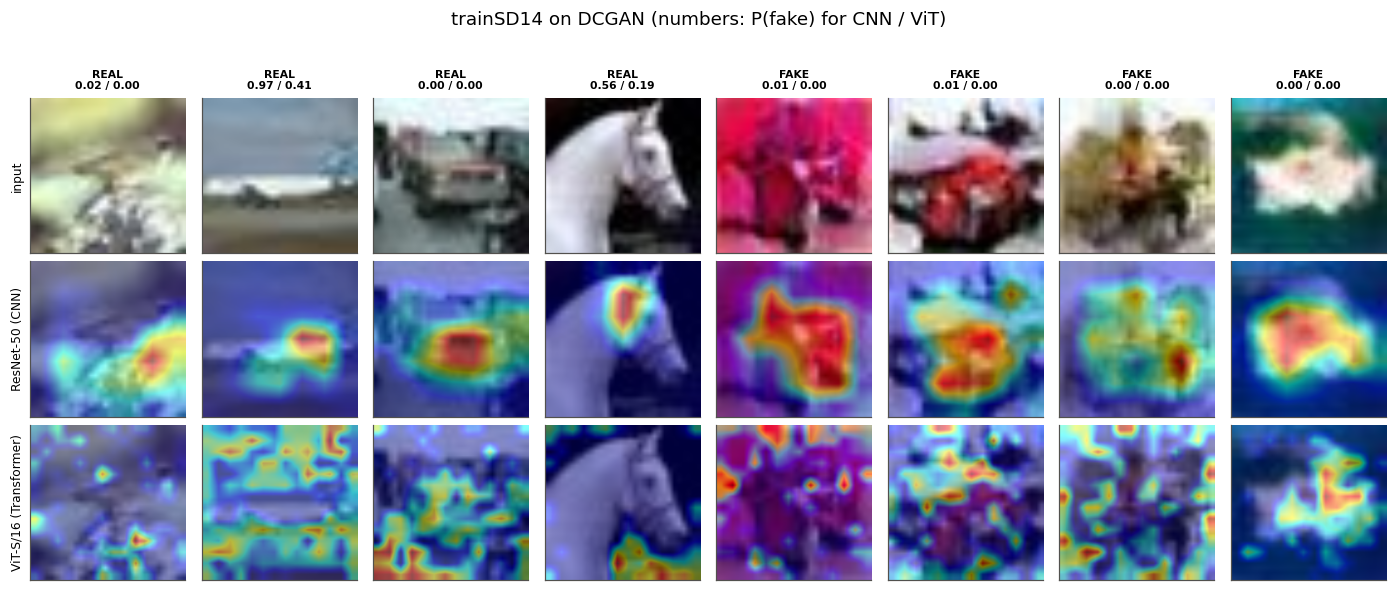

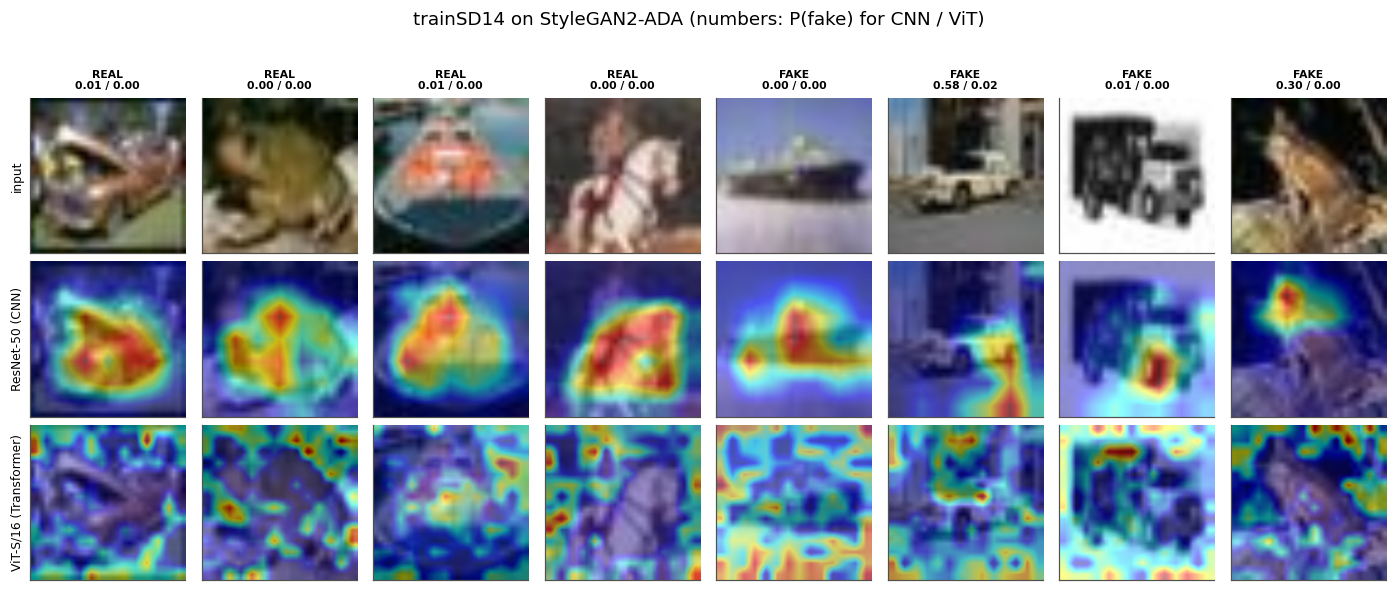

label                                    FAKE       REAL
test_set       setup     model                          
test_dcgan     trainSD14 resnet50    9.400000  48.400002
                         vit_small  26.799999  20.100000
               trainSD21 resnet50    3.100000  47.799999
                         vit_small  28.299999  26.900000
test_stylegan2 trainSD14 resnet50   14.100000  47.799999
                         vit_small  35.400002  19.799999
               trainSD21 resnet50    6.300000  49.000000
                         vit_small  31.400000  25.200001

In [46]:
def gradcam_layer(model):
    if model.family == "vit":
        return [model.backbone.blocks[-1].norm1]
    return [model.backbone.layer4[-1]]


def vit_reshape(model):
    n_prefix = getattr(model.backbone, "num_prefix_tokens", 1)
    gh, gw = model.backbone.patch_embed.grid_size

    def reshape(tokens):
        tokens = tokens[:, n_prefix:, :]
        return tokens.reshape(tokens.size(0), gh, gw, tokens.size(2)).permute(0, 3, 1, 2)
    return reshape


def gradcam(model, x_uint8, target_class=None, batch_size=32):
    # Heatmaps [N, 224, 224] in 0..1 and the matching upsampled images (as in notebook 03)
    reshape = vit_reshape(model) if model.family == "vit" else None
    cams, imgs = [], []
    with GradCAM(model=model, target_layers=gradcam_layer(model), reshape_transform=reshape) as cam:
        for i in range(0, len(x_uint8), batch_size):
            xb = to_float(torch.from_numpy(x_uint8[i:i + batch_size]).to(device))
            xb = F.interpolate(xb, size=(model.input_size, model.input_size), mode="bilinear", align_corners=False)
            targets = None if target_class is None else [ClassifierOutputTarget(target_class)] * len(xb)
            cams.append(cam(input_tensor=xb, targets=targets))
            imgs.append(xb.permute(0, 2, 3, 1).cpu().numpy())
    return np.concatenate(cams), np.clip(np.concatenate(imgs), 0, 1)


def center_share(cams, frac=0.5):
    n, h, w = cams.shape
    ch, cw = int(h * frac), int(w * frac)
    top, left = (h - ch) // 2, (w - cw) // 2
    return cams[:, top:top + ch, left:left + cw].reshape(n, -1).sum(1) / (cams.reshape(n, -1).sum(1) + 1e-8)


rng = np.random.default_rng(SEED)
setup = "trainSD14"
for tname in sweep_sets:
    x, y = test_sets[tname]
    idx = np.concatenate([rng.choice(np.flatnonzero(y == lab), 4, replace=False) for lab in (REAL, FAKE)])
    overlays = {}
    for m in MODELS:
        cams, imgs = gradcam(all_models[(setup, m, 42, False)], x[idx])
        overlays[m] = [show_cam_on_image(i.astype(np.float32), c, use_rgb=True, image_weight=0.55)
                       for i, c in zip(imgs, cams)]
    fig, axes = plt.subplots(1 + len(MODELS), len(idx), figsize=(1.6 * len(idx), 1.75 * (1 + len(MODELS))))
    for j, i in enumerate(idx):
        p = " / ".join(f"{P[((setup, m, 42, False), tname)][i]:.2f}" for m in MODELS)
        axes[0, j].imshow(imgs[j])
        axes[0, j].set_title(f"{LABEL_NAMES[y[i]]}\n{p}", fontsize=7)
        for r, m in enumerate(MODELS, start=1):
            axes[r, j].imshow(overlays[m][j])
        for r in range(1 + len(MODELS)):
            axes[r, j].set_xticks([]); axes[r, j].set_yticks([]); axes[r, j].grid(False)
    axes[0, 0].set_ylabel("input", fontsize=8)
    for r, m in enumerate(MODELS, start=1):
        axes[r, 0].set_ylabel(names[m], fontsize=8)
    fig.suptitle(f"{setup} on {GAN_TEST_SETS[tname]} (numbers: P(fake) for CNN / ViT)", y=1.02)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"05_gradcam_{setup}_{tname}.png")
    plt.show()

rows = []
for (s, m) in models42:
    for tname in sweep_sets:
        x, y = test_sets[tname]
        for lab in (REAL, FAKE):
            idx = rng.choice(np.flatnonzero(y == lab), GRADCAM_IMAGES // 2, replace=False)
            cams, _ = gradcam(all_models[(s, m, 42, False)], x[idx], target_class=lab)
            rows += [{"setup": s, "model": m, "test_set": tname, "label": LABEL_NAMES[lab], "center_share": v}
                     for v in center_share(cams)]
gan_attention = pd.DataFrame(rows)
gan_attention.to_csv(RESULTS_DIR / "05_gradcam_center_share.csv", index=False)
(gan_attention.groupby(["test_set", "setup", "model", "label"]).center_share.mean().unstack() * 100).round(1)

**What this shows.** On GAN fakes the CNN puts only 3 to 14% of its attention in the centre quarter (25% would be even), against about 48% on real photographs, so it looks at the edges when it sees a GAN image. The ViTs stay spread out (20 to 35%).

## 13 · Detection rate by object class

The GAN fakes have known classes (1,000 each), so it is possible to check whether some objects are harder to catch. Each value is the share of that class's fakes detected, averaged over the three seeds.

In [47]:
rows = []
for tname in sweep_sets:
    y, c = test_sets[tname][1], test_classes[tname]
    for run in [r for r in available_runs if not r[3]]:
        caught = P[(run, tname)] >= 0.5
        for k, cls in enumerate(CIFAR10_CLASSES):
            sel = (y == FAKE) & (c == k)
            rows.append({"setup": run[0], "model": run[1], "seed": run[2], "test_set": tname, "class": cls,
                         "n": int(sel.sum()), "fake_acc": caught[sel].mean() * 100})
gan_per_class_all = pd.DataFrame(rows)
gan_per_class_all.to_csv(RESULTS_DIR / "05_per_class_fake_accuracy_all_runs.csv", index=False)
gan_per_class = (gan_per_class_all.groupby(["test_set", "setup", "model", "class"], sort=False)
                 [["n", "fake_acc"]].mean().reset_index())
gan_per_class.to_csv(RESULTS_DIR / "05_per_class_fake_accuracy.csv", index=False)

rows = []
for (t, s, m), g in gan_per_class.groupby(["test_set", "setup", "model"], sort=False):
    lo, hi = g.loc[g.fake_acc.idxmin()], g.loc[g.fake_acc.idxmax()]
    rows.append({"test_set": GAN_TEST_SETS[t], "setup": s, "model": names[m],
                 "hardest class": lo["class"], "hardest %": lo.fake_acc,
                 "easiest class": hi["class"], "easiest %": hi.fake_acc})
pd.DataFrame(rows).round(1)

,test_set,setup,model,hardest class,hardest %,easiest class,easiest %
0,DCGAN,trainSD14,ResNet-50 (CNN),deer,0.5,airplane,4.9
1,DCGAN,trainSD14,ViT-S/16 (Transformer),cat,0.0,airplane,0.6
2,DCGAN,trainSD21,ResNet-50 (CNN),deer,0.4,ship,2.1
3,DCGAN,trainSD21,ViT-S/16 (Transformer),cat,0.1,ship,1.9
4,StyleGAN2-ADA,trainSD14,ResNet-50 (CNN),frog,2.8,airplane,15.0
5,StyleGAN2-ADA,trainSD14,ViT-S/16 (Transformer),frog,0.3,airplane,5.8
6,StyleGAN2-ADA,trainSD21,ResNet-50 (CNN),dog,1.5,bird,4.8
7,StyleGAN2-ADA,trainSD21,ViT-S/16 (Transformer),automobile,0.2,airplane,1.7


**What this shows.** No class stands out: even the easiest class (usually airplane) is caught at most 15% of the time, by the SD 1.4 CNN on StyleGAN2-ADA. The failure is general and does not depend on the object.

## 14 · An adversarial forger: training a GAN to fool a specific detector

The ethics section of the paper warns that a public detector can be used by forgers, who can train a generator against it, just as a GAN's generator is trained against its discriminator. This section tests that directly.

The trained DCGAN is fine-tuned for a short time with one extra term in the generator's loss: the frozen detector's cross-entropy for labelling the fake as **real**. The DCGAN's own discriminator keeps training as normal, so the images must still look like CIFAR-10 images. This is done twice, once against the seed-42 CNN and once against the seed-42 ViT, both trained on SD 1.4:

- **White-box result:** how often the targeted detector still catches the new fakes.
- **Transfer:** whether fakes made to fool one detector also fool the *other* architecture, the other seeds and the augmented models, which the forger never saw.
- **Cost:** how much realism the forger gives up (FID), and what the changes look like. The same latent vectors are used before and after fine-tuning, so the images can be compared side by side.

The forger is trained on raw images, but its fakes are evaluated after the same JPEG step as every other test set, as would happen if they were posted online.

Adversarial forger against ResNet-50 (CNN) found (1000 steps)
Adversarial forger against ViT-S/16 (Transformer) found (1000 steps)


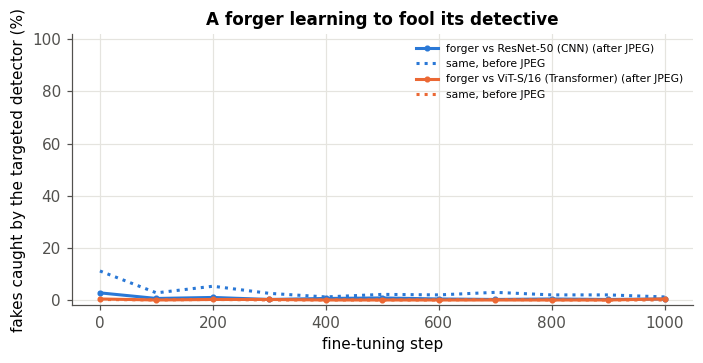

In [48]:
ADV_SETUP = "trainSD14"
ADV_STEPS = 1_000
ADV_BATCH = 64
ADV_LAMBDA = 1.0          # weight of the "fool the detector" term against the usual GAN loss
ADV_MONITOR = 512         # fixed images used to track the detector's score during training


def train_adversarial_forger(target_key):
    # Fine-tune a copy of the DCGAN against one frozen detector; resumes from the last saved step.
    ckpt_path = GAN_MODEL_DIR / f"dcgan_adv_vs_{run_name(ADV_SETUP, target_key)}.pt"
    detector = all_models[(ADV_SETUP, target_key, 42, False)]
    G, D = copy.deepcopy(G_dc), copy.deepcopy(D_dc)
    opt_g = torch.optim.Adam(G.parameters(), lr=DCGAN_LR, betas=DCGAN_BETAS)
    opt_d = torch.optim.Adam(D.parameters(), lr=DCGAN_LR, betas=DCGAN_BETAS)
    history, start = [], 0
    if ckpt_path.exists():
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        for obj, key in ((G, "G"), (D, "D"), (opt_g, "opt_g"), (opt_d, "opt_d")):
            obj.load_state_dict(ckpt[key])
        history, start = ckpt["history"], ckpt["step"]
    if start >= ADV_STEPS:
        print(f"Adversarial forger against {names[target_key]} found ({start} steps)")
        return G.eval(), pd.DataFrame(history)

    monitor_y = torch.as_tensor(FAKE_CLASSES[::N_FAKE // ADV_MONITOR][:ADV_MONITOR], device=device)
    monitor_z = torch.randn(len(monitor_y), Z_DIM, device=device,
                            generator=torch.Generator(device=device).manual_seed(GEN_SEED))

    def monitor(step):
        G.eval()
        with torch.no_grad():
            imgs = to_uint8(G(monitor_z, monitor_y))
        G.train()
        raw = predict_proba(detector, imgs)
        jpg = predict_proba(detector, jpeg_roundtrip(imgs))
        history.append({"step": step, "mean_p_fake_raw": float(raw.mean()), "mean_p_fake_jpeg": float(jpg.mean()),
                        "caught_raw_pct": float((raw >= 0.5).mean() * 100),
                        "caught_jpeg_pct": float((jpg >= 0.5).mean() * 100)})

    def fool_detector(fake_pm1):
        # Cross-entropy of the frozen detector for calling the fake REAL (the forger's extra goal)
        logits = detector((fake_pm1 + 1) / 2)
        return ADV_LAMBDA * F.cross_entropy(logits, torch.full((len(logits),), REAL, device=device))

    detector.eval()
    detector.requires_grad_(False)          # the detector is frozen; only the forger learns
    try:
        if start == 0:
            monitor(0)
        torch.manual_seed(SEED + 1000 + start)
        G.train()
        D.train()
        for step in tqdm(range(start + 1, ADV_STEPS + 1), desc=f"Forger vs {names[target_key]}"):
            idx = torch.randint(0, len(X_cifar), (ADV_BATCH,), device=device)
            x, y = real_batch(X_cifar, Y_cifar, idx)
            gan_step(G, D, opt_g, opt_d, x, y, extra_g_loss=fool_detector)
            if step % 100 == 0:
                monitor(step)
                torch.save({"G": G.state_dict(), "D": D.state_dict(), "opt_g": opt_g.state_dict(),
                            "opt_d": opt_d.state_dict(), "step": step, "history": history}, ckpt_path)
    finally:
        detector.requires_grad_(True)       # Grad-CAM and other sections need gradients again
    return G.eval(), pd.DataFrame(history)


adv_generators, adv_history = {}, {}
for target_key in MODELS:
    adv_generators[target_key], adv_history[target_key] = train_adversarial_forger(target_key)
    adv_history[target_key].assign(target=target_key).to_csv(
        RESULTS_DIR / f"05_adversarial_training_{target_key}.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for target_key, h in adv_history.items():
    ax.plot(h.step, h.caught_jpeg_pct, "-o", color=MODEL_COLORS[target_key], markersize=3,
            label=f"forger vs {names[target_key]} (after JPEG)")
    ax.plot(h.step, h.caught_raw_pct, ":", color=MODEL_COLORS[target_key], label="same, before JPEG")
ax.set(xlabel="fine-tuning step", ylabel="fakes caught by the targeted detector (%)", ylim=(-2, 102),
       title="A forger learning to fool its detective")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_adversarial_training.png")
plt.show()

In [49]:
# Test sets of adversarial fakes (same latent vectors and classes as the clean DCGAN set)
ADV_TEST_SETS = {}
for target_key, G_adv in adv_generators.items():
    tname = f"test_adv_{target_key}"
    raw = cached_raw(f"dcgan_adv_{target_key}", lambda z, y, G_adv=G_adv: G_adv(z, y), Z_DIM)
    x, y, c = build_test_set(tname, jpeg_roundtrip(raw), FAKE_CLASSES)
    test_sets[tname], test_classes[tname] = (x, y), c
    ADV_TEST_SETS[tname] = f"DCGAN fine-tuned against {names[target_key]}"
    raw_fakes[f"adv_{target_key}"] = raw

# Every detector on every adversarial set, with the clean DCGAN set as the baseline
y_dcgan = test_sets["test_dcgan"][1]
rows = []
for run in available_runs:
    for tname in ADV_TEST_SETS:
        x, y = test_sets[tname]
        P[(run, tname)] = p = cached_predictions(run, tname)
        base = P[(run, "test_dcgan")]
        rows.append({"forger_target": tname.replace("test_adv_", ""), "setup": run[0], "model": run[1],
                     "seed": run[2], "augment": run[3],
                     "is_target": run == (ADV_SETUP, tname.replace("test_adv_", ""), 42, False),
                     "fake_acc_clean_dcgan": (base[y_dcgan == FAKE] >= 0.5).mean() * 100,
                     **{k: v for k, v in compute_metrics(y, p).items() if k in KEY}})
adv_all = pd.DataFrame(rows)
adv_all["fake_acc_change"] = adv_all.fake_acc - adv_all.fake_acc_clean_dcgan
adv_all.to_csv(RESULTS_DIR / "05_adversarial_all_runs.csv", index=False)

# White-box result before JPEG (the forger's raw output), for the targeted detectors only
for target_key in MODELS:
    p_raw = predict_proba(all_models[(ADV_SETUP, target_key, 42, False)], raw_fakes[f"adv_{target_key}"])
    print(f"Forger vs {names[target_key]}: the targeted detector catches {(p_raw >= 0.5).mean() * 100:.1f}% "
          f"of the raw fakes (before JPEG)")


def group(r):
    if r.is_target:
        return "targeted detector (seed 42)"
    if r.augment:
        return "augmented models"
    same = r.model == r.forger_target
    return ("same architecture, " if same else "other architecture, ") + \
           ("same training data" if r.setup == ADV_SETUP else "other training data")


adv_all["group"] = adv_all.apply(group, axis=1)
transfer = (adv_all.groupby(["forger_target", "group"], sort=False)
            [["fake_acc_clean_dcgan", "fake_acc", "fake_acc_change", "auroc"]].mean().round(1))
transfer.to_csv(RESULTS_DIR / "05_adversarial_transfer.csv")
display(transfer)

# Realism cost: FID of the adversarial fakes, added to the FID table
for tname, label in ADV_TEST_SETS.items():
    if label not in set(fid_table.generator):
        x, y = test_sets[tname]
        fid_table.loc[len(fid_table)] = [label, fid_against_real(x[y == FAKE])]
        fid_table.to_csv(FID_FILE, index=False)
fid_table.round(2)

Forger vs ResNet-50 (CNN): the targeted detector catches 1.4% of the raw fakes (before JPEG)
Forger vs ViT-S/16 (Transformer): the targeted detector catches 0.1% of the raw fakes (before JPEG)


,,fake_acc_clean_dcgan,fake_acc,fake_acc_change,auroc
forger_target,group,,,,
resnet50,targeted detector (seed 42),2.2,0.2,-2.0,30.9
vit_small,"other architecture, same training data",1.9,1.2,-0.7,38.3
resnet50,"other architecture, same training data",0.2,0.0,-0.2,21.7
vit_small,targeted detector (seed 42),0.2,0.1,-0.1,28.3
resnet50,"same architecture, other training data",0.9,0.2,-0.7,40.6
vit_small,"other architecture, other training data",0.9,0.8,-0.0,46.2
resnet50,"other architecture, other training data",0.7,0.2,-0.5,34.6
vit_small,"same architecture, other training data",0.7,0.6,-0.1,43.2
resnet50,augmented models,1.4,0.9,-0.6,38.2


,generator,fid_10k
0,DCGAN,29.36
1,StyleGAN2-ADA,6.15
2,SD 1.4,31.40
3,SD 2.1,40.77
4,SD 3.0,36.40
5,DCGAN fine-tuned against ResNet-50 (CNN),36.88
6,DCGAN fine-tuned against ViT-S/16 (Transformer),33.35


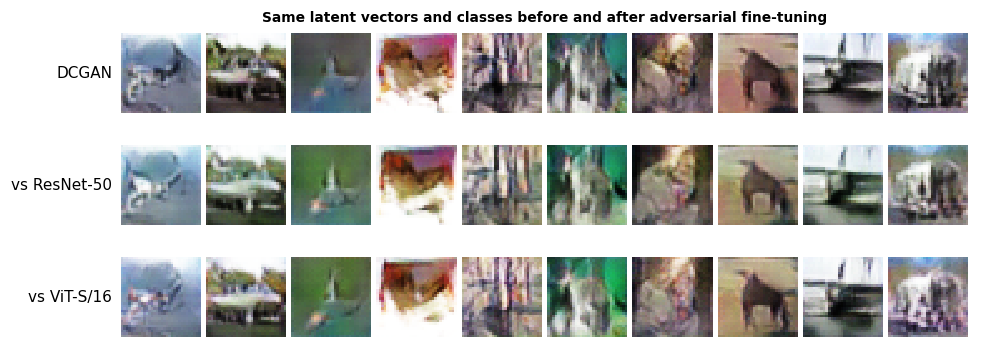

In [50]:
# Same latent vectors before and after fine-tuning: clean DCGAN vs each adversarial forger
show = np.array([np.flatnonzero(FAKE_CLASSES == k)[0] for k in range(10)])
rows = [("DCGAN", raw_fakes["dcgan"][show])]
rows += [(f"vs {names[k].split(' ')[0]}", raw_fakes[f"adv_{k}"][show]) for k in MODELS]
fig, axes = plt.subplots(len(rows), 1, figsize=(10, 1.25 * len(rows)))
for ax, (label, imgs) in zip(axes, rows):
    strip = np.concatenate([np.pad(i, ((1, 1), (1, 1), (0, 0)), constant_values=255) for i in imgs], axis=1)
    ax.imshow(strip, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_ylabel(label, rotation=0, ha="right", va="center")
axes[0].set_title("Same latent vectors and classes before and after adversarial fine-tuning", fontsize=9)
fig.savefig(FIG_DIR / "05_adversarial_samples.png")
plt.show()

**What this shows.** The forger lowered the targeted CNN's catch rate from 2.2% to 0.2% and the targeted ViT's from 0.2% to 0.1%, and no group of models caught more than 1.6% of its fakes. Since the clean DCGAN already fooled every detector, the forger had very little left to gain, and it cost some realism (FID 29.4 to 36.9 and 33.3).

## 15 · Summary of key results

This summary is generated from the result tables, so it always matches them.

In [51]:
def stat(setup, m, t, col="accuracy"):
    sel = lambda d: d[(d.setup == setup) & (d.model == m) & (d.test_set == t)][col].item()
    return sel(both_mean), sel(both_std)


lines = ["### GAN experiment: key results (mean ± SD over three seeds)\n"]
lines.append("**Realism (FID-10k, lower = more realistic):** "
             + ", ".join(f"{r.generator} {r.fid_10k:.1f}" for r in fid_table.itertuples()) + "\n")
for setup in TRAIN_SETUPS:
    lines.append(f"**{setup}**\n")
    for t in GAN_TEST_SETS:
        (a, sa), (b, sb) = stat(setup, cnn, t), stat(setup, vit, t)
        fa, fb = stat(setup, cnn, t, "fake_acc")[0], stat(setup, vit, t, "fake_acc")[0]
        ua, ub = stat(setup, cnn, t, "auroc")[0], stat(setup, vit, t, "auroc")[0]
        c = gan_consistency.loc[(setup, t)]
        rc = gan_recal[(gan_recal.setup == setup) & (gan_recal.test_set == t)].set_index("model")
        lines.append(f"- {GAN_TEST_SETS[t]}: accuracy CNN {a:.1f} ± {sa:.1f} vs ViT {b:.1f} ± {sb:.1f}; "
                     f"fakes caught {fa:.1f} vs {fb:.1f}; AUROC {ua:.1f} vs {ub:.1f}; "
                     f"recalibrated {rc.loc[cnn, 'acc_recalibrated']:.1f} vs {rc.loc[vit, 'acc_recalibrated']:.1f}; "
                     f"ViT better in {c.ViT_better_in}/{c.seeds} seeds, significant in {c.significant_in}/{c.seeds}")
    lines.append("")
lines.append("**Adversarial forger (share of fakes caught: clean DCGAN → adversarial):**\n")
for (target, g), r in transfer.iterrows():
    lines.append(f"- forger vs {names[target]}, {g}: {r.fake_acc_clean_dcgan:.1f} → {r.fake_acc:.1f} "
                 f"(AUROC {r.auroc:.1f})")
summary_text = "\n".join(lines)
(RESULTS_DIR / "05_key_results.md").write_text(summary_text)
display(Markdown(summary_text))

### GAN experiment: key results (mean ± SD over three seeds)

**Realism (FID-10k, lower = more realistic):** DCGAN 29.4, StyleGAN2-ADA 6.1, SD 1.4 31.4, SD 2.1 40.8, SD 3.0 36.4, DCGAN fine-tuned against ResNet-50 (CNN) 36.9, DCGAN fine-tuned against ViT-S/16 (Transformer) 33.3

**trainSD14**

- DCGAN: accuracy CNN 48.4 ± 0.1 vs ViT 49.1 ± 0.2; fakes caught 1.9 vs 0.2; AUROC 43.2 vs 30.1; recalibrated 48.8 vs 49.1; ViT better in 3.0/3.0 seeds, significant in 3.0/3.0
- DCGAN blurred: accuracy CNN 77.2 ± 2.7 vs ViT 49.8 ± 1.1; fakes caught 59.4 vs 1.5; AUROC 93.4 vs 85.8; recalibrated 87.6 vs 78.3; ViT better in 0.0/3.0 seeds, significant in 3.0/3.0
- StyleGAN2-ADA: accuracy CNN 50.8 ± 0.1 vs ViT 50.2 ± 0.1; fakes caught 6.8 vs 2.4; AUROC 54.2 vs 52.2; recalibrated 52.7 vs 51.1; ViT better in 0.0/3.0 seeds, significant in 3.0/3.0
- StyleGAN2-ADA blurred: accuracy CNN 78.8 ± 4.3 vs ViT 51.1 ± 2.3; fakes caught 62.7 vs 4.2; AUROC 93.5 vs 87.5; recalibrated 88.1 vs 81.0; ViT better in 0.0/3.0 seeds, significant in 3.0/3.0

**trainSD21**

- DCGAN: accuracy CNN 49.2 ± 0.1 vs ViT 50.0 ± 0.1; fakes caught 0.9 vs 0.7; AUROC 46.2 vs 39.6; recalibrated 47.8 vs 49.9; ViT better in 3.0/3.0 seeds, significant in 3.0/3.0
- DCGAN blurred: accuracy CNN 72.7 ± 2.8 vs ViT 50.6 ± 1.0; fakes caught 48.0 vs 1.8; AUROC 95.2 vs 93.5; recalibrated 89.3 vs 84.6; ViT better in 0.0/3.0 seeds, significant in 3.0/3.0
- StyleGAN2-ADA: accuracy CNN 50.0 ± 0.0 vs ViT 50.1 ± 0.0; fakes caught 2.6 vs 0.9; AUROC 51.0 vs 49.7; recalibrated 50.5 vs 50.1; ViT better in 2.0/3.0 seeds, significant in 0.0/3.0
- StyleGAN2-ADA blurred: accuracy CNN 70.9 ± 4.1 vs ViT 50.8 ± 1.2; fakes caught 44.3 vs 2.2; AUROC 94.3 vs 93.0; recalibrated 88.1 vs 83.3; ViT better in 0.0/3.0 seeds, significant in 3.0/3.0

**Adversarial forger (share of fakes caught: clean DCGAN → adversarial):**

- forger vs ResNet-50 (CNN), targeted detector (seed 42): 2.2 → 0.2 (AUROC 30.9)
- forger vs ViT-S/16 (Transformer), other architecture, same training data: 1.9 → 1.2 (AUROC 38.3)
- forger vs ResNet-50 (CNN), other architecture, same training data: 0.2 → 0.0 (AUROC 21.7)
- forger vs ViT-S/16 (Transformer), targeted detector (seed 42): 0.2 → 0.1 (AUROC 28.3)
- forger vs ResNet-50 (CNN), same architecture, other training data: 0.9 → 0.2 (AUROC 40.6)
- forger vs ViT-S/16 (Transformer), other architecture, other training data: 0.9 → 0.8 (AUROC 46.2)
- forger vs ResNet-50 (CNN), other architecture, other training data: 0.7 → 0.2 (AUROC 34.6)
- forger vs ViT-S/16 (Transformer), same architecture, other training data: 0.7 → 0.6 (AUROC 43.2)
- forger vs ResNet-50 (CNN), augmented models: 1.4 → 0.9 (AUROC 38.2)
- forger vs ViT-S/16 (Transformer), augmented models: 1.4 → 1.6 (AUROC 41.5)
- forger vs ResNet-50 (CNN), same architecture, same training data: 1.8 → 0.2 (AUROC 29.7)
- forger vs ViT-S/16 (Transformer), same architecture, same training data: 0.2 → 0.2 (AUROC 30.8)

### References

- Frank, J., et al. (2020). Leveraging frequency analysis for deep fake image recognition. *ICML*. https://arxiv.org/abs/2003.08685
- Goodfellow, I., et al. (2014). Generative adversarial nets. *NeurIPS*. https://arxiv.org/abs/1406.2661
- Grommelt, P., et al. (2024). Fake or JPEG? Revealing common biases in generated image detection datasets. https://arxiv.org/abs/2403.17608
- Heusel, M., et al. (2017). GANs trained by a two time-scale update rule converge to a local Nash equilibrium. *NeurIPS*. https://arxiv.org/abs/1706.08500
- Jiang, J. (2024). Addressing vulnerabilities in AI-image detection: Challenges and proposed solutions. https://arxiv.org/abs/2412.00073
- Karras, T., et al. (2020). Training generative adversarial networks with limited data. *NeurIPS*. https://arxiv.org/abs/2006.06676
- Mirza, M., & Osindero, S. (2014). Conditional generative adversarial nets. https://arxiv.org/abs/1411.1784
- Radford, A., Metz, L., & Chintala, S. (2016). Unsupervised representation learning with deep convolutional generative adversarial networks. *ICLR*. https://arxiv.org/abs/1511.06434